# Long Short-Term Memory Networks


LSTM is a type of recurrent neural network(RNN) architecture designed to capture long-term temporal dependencies and highly non-linear dynamics in sequential data (Shi, et al., 2022; Hewamalage, et al., 2019). 

# Experiment 1:

Build and fine tune a LSTM model using the **Dublin weather dataset**, **neither differencing nor log transformation techniques has been applied** for this experiment.

### Libraries

In [1]:
# Data manipulation
import numpy as np
import pandas as pd

# Scalling
from sklearn.preprocessing import MinMaxScaler
#  LSTM Model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Bidirectional
from tensorflow.keras.optimizers import Adam

# Early Stopping
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Plots
import matplotlib.pyplot as plt
import seaborn as sns

# Keras for randomsearch
import tensorflow as tf
import keras_tuner as kt
from sklearn.model_selection import ParameterGrid

# Statiscal Evaluation Metrics
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, mean_absolute_percentage_error
from math import sqrt

#to correct data
from sklearn.linear_model import LinearRegression
# Suppress all warnings
import warnings
warnings.filterwarnings("ignore")

## Load the Data

In [2]:
df = pd.read_csv("Datasets/dublin_2015_to_2024_final.csv", parse_dates=["datetime"])
df = df.sort_index()


- parse_dates = ["datetime"] the time order is explicit
- sort_index() is to avoid shuffling 

## Split data into Train(8 years) and Test(2 years)

The dataset was devided into train and test, with the purpuse of having real data for comparing model's prediction data

In [3]:
train = df[df['datetime'] < '2022-12-31']
test = df[df['datetime'] >= '2022-12-31'].copy()

set index

In [4]:
train.set_index("datetime", inplace=True)
test.set_index("datetime", inplace=True)


In [5]:
train.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2921 entries, 2015-01-01 to 2022-12-30
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   tempmax           2921 non-null   float64
 1   humidity          2921 non-null   float64
 2   precip            2921 non-null   float64
 3   windgust          2921 non-null   float64
 4   windspeed         2921 non-null   float64
 5   winddir           2921 non-null   float64
 6   sealevelpressure  2921 non-null   float64
 7   cloudcover        2921 non-null   float64
 8   visibility        2921 non-null   float64
 9   solarradiation    2921 non-null   float64
dtypes: float64(10)
memory usage: 251.0 KB


Note:

column 9 is the target feature

In [17]:
test.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 732 entries, 2022-12-31 to 2024-12-31
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   tempmax           732 non-null    float64
 1   humidity          732 non-null    float64
 2   precip            732 non-null    float64
 3   windgust          732 non-null    float64
 4   windspeed         732 non-null    float64
 5   winddir           732 non-null    float64
 6   sealevelpressure  732 non-null    float64
 7   cloudcover        732 non-null    float64
 8   visibility        732 non-null    float64
 9   solarradiation    732 non-null    float64
dtypes: float64(10)
memory usage: 62.9 KB


## Scaling

MinMaxScaler scale the data into a range or 0-1

In [5]:
y=train['solarradiation'].values

In [6]:
scaler = MinMaxScaler()
scaler_t = MinMaxScaler()
train_scaled = scaler.fit_transform(train)
test_scaled= scaler_t.fit_transform(test)

In [7]:
scaler_y=MinMaxScaler()
y_scaled=scaler_y.fit_transform(y.reshape(-1,1))

In [34]:
y.shape,y_scaled.shape

((2921,), (2921, 1))

## Make sequences

The create_sequence() function below divide the sequence into input/output patterns called samples, where lookback are the time steps used as input and horizon is the prediction

In [8]:
lookback = 30 # 30 days in memory
horizon = 1 # predicts next day

In [9]:
def create_sequences(data, lookback, horizon):
    X, y = [], []
    
    for i in range(lookback, len(data)- horizon+1):
        X.append(data[i-lookback:i,:])
        y.append(data[i + horizon-1, 9])  # 9 is Solarradiation feature
    return np.array(X), np.array(y)


- lookbak = how much past information is in memory
- horizon = how far ahead is predicting (1 predicts next day)

## X_train and y_train

computing create_sequences() function to create samples from train_scaled dataset

In [10]:
#Build train sequences from train_scaled

X_train, y_train = create_sequences(train_scaled, lookback, horizon)

In [121]:

X_train.shape

(2891, 30, 10)

In [11]:
y_train.shape

(2891,)

## History for test

test need some history, the last lookback rows are concatenated at the beginning of test

In [11]:
history = train_scaled[-lookback:,:]
test_history= np.vstack([history, test_scaled])

In [34]:
test_history.shape

(762, 10)

## create X_test, y_test

In [12]:
X_test, y_test = create_sequences(test_history, lookback, horizon)

In [15]:
X_test.shape,y_test.shape

((732, 30, 10), (732,))

## Build the  LSTM Model

The first layer that is added is an LSTM layer. The LSTM class accept several parameters:

- units, the number of LSTM neurons that are included in this layer
- return_sequences = True, this indicates that another LSTM layer will be added after the current layer already added.
- intup_shape, the number of timesteps and the number of predictors in out trainign data. Predictor is 1 ('solarradiation')

**Dropout regularization** is a technique used to avoid overfitting when training neural networks.
It involves randomly excluding or dropping out certain layer outputs during the training stage.
The dropout rate indicates how many neurons should be dropped in a specific layer of the neural network.

**Output Layer**, the Dense class will be the output layer. The parameter that has to be specified is units, which is the desired number of dimentions that the output layer should generate. 

TensorFlows allows to compile a nueral network, it accepts two arguments: optimizer and loss.

The Adam optimizer is useful in a wide variety of neural networks architectures.
The loss parameter is mean squared error, this is to measure the performance.

In [21]:
model = Sequential([
    LSTM( 128,activation='relu',recurrent_activation='sigmoid' ,return_sequences=True, input_shape=(lookback, X_train.shape[2])),
    Dropout(0.2),
    #Dense(horizon)
])
model.add(LSTM(units = 128,activation='relu',recurrent_activation='sigmoid' , return_sequences = True))

model.add(Dropout(0.2))

model.add(LSTM(units = 128,activation='relu',recurrent_activation='sigmoid' , return_sequences = True))

model.add(Dropout(0.2))

model.add(LSTM(units = 128,activation='relu',recurrent_activation='sigmoid' ))

model.add(Dropout(0.2))
model.add(Dense(units=1))
model.compile(optimizer='adam', loss='mse')
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm_4 (LSTM)                        │ (None, 30, 128)             │          71,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 30, 128)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_5 (LSTM)                        │ (None, 30, 128)             │         131,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_5 (Dropout)                  │ (None, 30, 128)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_6 (LSTM)                        │ (None, 30, 128)             │         131,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_6 (Dropout)                  │ (None, 30, 128)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_7 (LSTM)                        │ (None, 128)                 │         131,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_7 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 466,049 (1.78 MB)

 Trainable params: 466,049 (1.78 MB)

 Non-trainable params: 0 (0.00 B)

## Training the Model

**EarlyStopping**

Stop training when a monitored metric has stopped improving. Assuming the goal of a training is to minimize the loss. 

In [16]:
es = EarlyStopping(monitor='val_loss', mode='min', verbose=1, patience=5)


The LSTM model is trained with X_train and y_train dataframes, 20% of the train data is been use as 'validation data'. This helps keras to evaluate loss on a separete dataset

In [22]:
history = model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=500,
    batch_size=32,
    callbacks=[es],
    shuffle=False,
    verbose=1
)


Epoch 1/500
73/73 ━━━━━━━━━━━━━━━━━━━━ 13s 85ms/step - loss: 0.1046 - val_loss: 0.0368
Epoch 2/500
73/73 ━━━━━━━━━━━━━━━━━━━━ 5s 71ms/step - loss: 0.0513 - val_loss: 0.0301
Epoch 3/500
73/73 ━━━━━━━━━━━━━━━━━━━━ 6s 79ms/step - loss: 0.0431 - val_loss: 0.0328
Epoch 4/500
73/73 ━━━━━━━━━━━━━━━━━━━━ 6s 84ms/step - loss: 0.0392 - val_loss: 0.0224
Epoch 5/500
73/73 ━━━━━━━━━━━━━━━━━━━━ 6s 79ms/step - loss: 0.0309 - val_loss: 0.0184
Epoch 6/500
73/73 ━━━━━━━━━━━━━━━━━━━━ 6s 81ms/step - loss: 0.0280 - val_loss: 0.0177
Epoch 7/500
73/73 ━━━━━━━━━━━━━━━━━━━━ 6s 86ms/step - loss: 0.0287 - val_loss: 0.0173
Epoch 8/500
73/73 ━━━━━━━━━━━━━━━━━━━━ 6s 77ms/step - loss: 0.0260 - val_loss: 0.0172
Epoch 9/500
73/73 ━━━━━━━━━━━━━━━━━━━━ 6s 84ms/step - loss: 0.0253 - val_loss: 0.0173
Epoch 10/500
73/73 ━━━━━━━━━━━━━━━━━━━━ 6s 84ms/step - loss: 0.0235 - val_loss: 0.0177
Epoch 11/500
73/73 ━━━━━━━━━━━━━━━━━━━━ 6s 83ms/step - loss: 0.0225 - val_loss: 0.0175
Epoch 12/500
73/73 ━━━━━━━━━━━━━━━━━━━━ 6s 78ms/ste

## Loss Plot

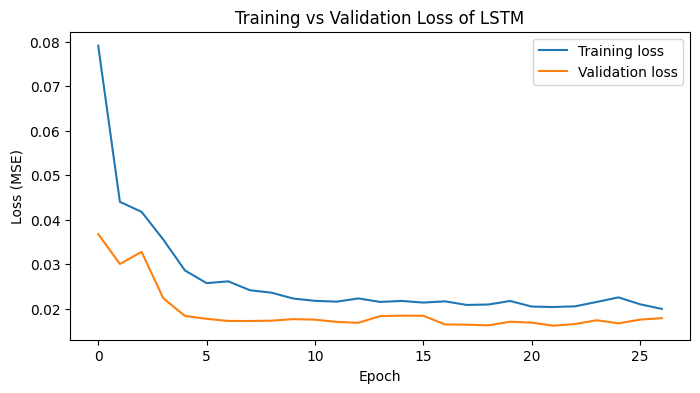

In [23]:
plt.figure(figsize=(8,4))
plt.plot(history.history['loss'], label='Training loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.title("Training vs Validation Loss of LSTM")
plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.legend()
plt.show()

Observations:
- Validation and training loss decrase
- Loss is stable
- no overfitting
- no underfitting

## Predict

In [24]:
y_pred = model.predict(X_test)


23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 49ms/step  


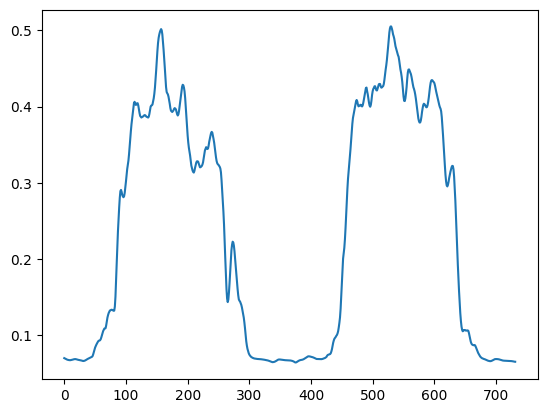

In [25]:
plt.plot(y_pred)

## Unscale

In [85]:
y_test_inv = scaler.inverse_transform(np.hstack((y_test.reshape(-1,1), #target 
                                                X_test[:, -1, 1:] # exogenous data last step
                                                )))[:,9] #take only the solarradiation units


In [42]:
y_pred.shape

(732, 1)

In [44]:
y_pred_inv = scaler_t.inverse_transform(y_pred.reshape(-1,1)) # solarradiation feature


ValueError: Expected 2D array, got 1D array instead:
array=[0.07007593].
Reshape your data either using array.reshape(-1, 1) if your data has a single feature or array.reshape(1, -1) if it contains a single sample.

In [32]:
y_pred_2=scaler_y.inverse_transform(y_pred.reshape(-1,1))

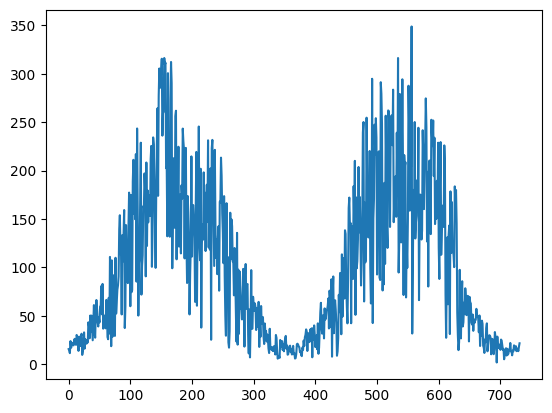

In [33]:
plt.plot(y_pred_inv)

## Actual vs Predicted Data Plot

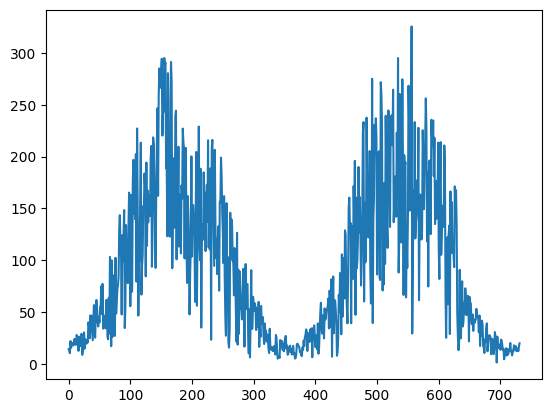

In [23]:
plt.plot(y_pred_inv)

In [55]:
y_pred_inv.shape

(732,)

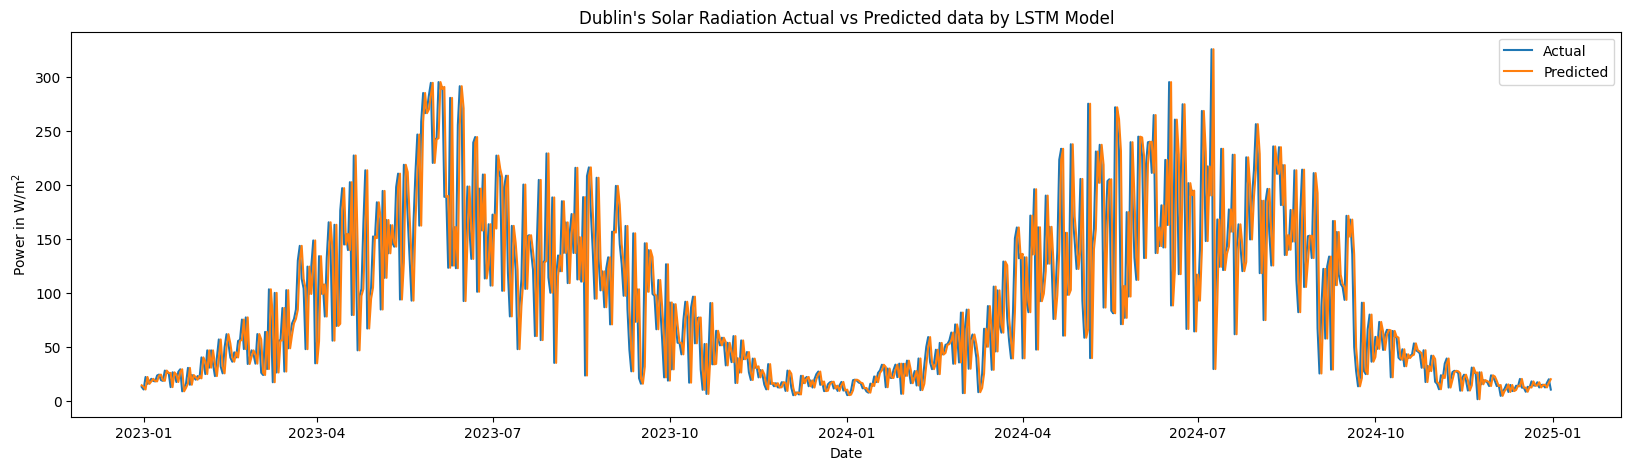

In [56]:
plt.figure(figsize=(20,5))
plt.plot(test.index,test['solarradiation'], label="Actual")
plt.plot(test.index,y_pred_inv, label="Predicted")
plt.legend()
plt.xlabel('Date')
plt.ylabel('Power in W/m$^2$')
plt.title("Dublin's Solar Radiation Actual vs Predicted data by LSTM Model")
plt.show()


In [107]:
y_test_inv.shape

(732,)

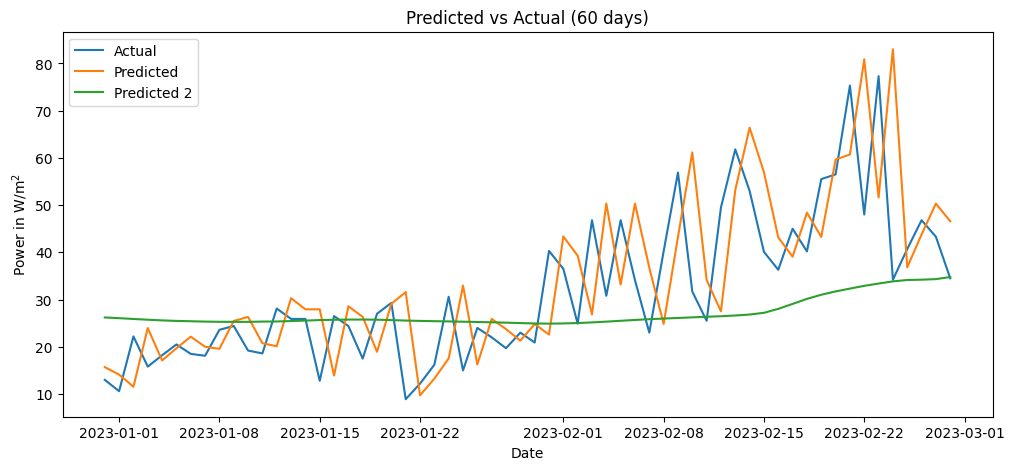

In [34]:
plt.figure(figsize=(12,5))
t=test['solarradiation']
#plt.plot(test.index[:60],y_test_inv[:60], label="Actual")
plt.plot(test.index[:60],t[:60], label="Actual")
plt.plot(test.index[:60],y_pred_inv[:60], label="Predicted")
plt.plot(test.index[:60],y_pred_2[:60], label="Predicted 2")
plt.legend()
plt.xlabel('Date')
plt.ylabel('Power in W/m$^2$')
plt.title("Predicted vs Actual (60 days)")
plt.show()

## Accuracy

In [74]:
# Compute accuracy metrics
rmse = np.sqrt(mean_squared_error(test['solarradiation'], y_pred_2))
mae = mean_absolute_error(test['solarradiation'], y_pred_2)
r2 = r2_score(test['solarradiation'], y_pred_2)
mape=mean_absolute_percentage_error(test['solarradiation'], y_pred_2)

print(f"RMSE: {rmse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"R² Score: {r2:.4f}")
print(f'MAPE: {mape:.4f}')

RMSE: 45.5773
MAE: 32.8605
R² Score: 0.6271
MAPE: 0.5676


In [147]:
# Compute accuracy metrics
rmse = np.sqrt(mean_squared_error(test['solarradiation'], y_pred_inv))
mae = mean_absolute_error(test['solarradiation'], y_pred_inv)
r2 = r2_score(test['solarradiation'], y_pred_inv)
mape=mean_absolute_percentage_error(test['solarradiation'], y_pred_inv)

print(f"RMSE: {rmse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"R² Score: {r2:.4f}")
print(f'MAPE: {mape:.4f}')

RMSE: 54.4403
MAE: 36.1265
R² Score: 0.4679
MAPE: 0.5604


In [47]:
# Symmetric Mean Absolute Percentae Error Function
def smape(test, pred):
    test, pred = np.array(test), np.array(pred)
    return 100 * np.mean(2 * np.abs(pred - test) /
                         (np.abs(test) + np.abs(pred) + 1e-8))

print("SMAPE:", smape(test['solarradiation'], y_pred_inv))

SMAPE: 42.03935927899308


## Fine tune by Grid Search

In [14]:
def build_lstm(input_shape, units=64, dropout=0.2, lr=0.001):
    model = Sequential([
        LSTM(units, input_shape=input_shape, return_sequences=False),
        Dropout(dropout),
        Dense(1)
    ])
    model.compile(
        optimizer=Adam(learning_rate=lr),
        loss='mse'
    )
    return model

In [15]:
param_grid = {
    'units': [32, 64,96, 128,256],
    'dropout': [0.1, 0.2, 0.3],
    'lr': [0.001, 0.0005,0.0002],
    "batch":([32, 64, 96])
    
}

In [16]:
best = {"val_loss": np.inf, "params": None, "model": None} #np.inf returns true positive
results = []


In [19]:
for p in ParameterGrid(param_grid):
    model = build_lstm(X_train.shape[1:], units=p["units"], dropout=p["dropout"], lr=p["lr"])
    
    hist = model.fit(
        X_train, y_train,
        validation_split=0.2,    
        epochs=5, 
        batch_size=p["batch"], 
        verbose=1, 
        callbacks=[es]
    )
    vl = float(np.min(hist.history["val_loss"]))
    results.append({**p, "val_loss": vl})
    if vl < best["val_loss"]:
        best = {"val_loss": vl, "params": p, "model": model}


Epoch 1/5
73/73 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.0747 - val_loss: 0.0232
Epoch 2/5
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0272 - val_loss: 0.0156
Epoch 3/5
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0229 - val_loss: 0.0149
Epoch 4/5
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0223 - val_loss: 0.0141
Epoch 5/5
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0203 - val_loss: 0.0142
Epoch 1/5
73/73 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.0556 - val_loss: 0.0180
Epoch 2/5
72/73 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0220 

KeyboardInterrupt: 

In [35]:
best

{'val_loss': 0.013538280501961708,
 'params': {'batch': 32, 'dropout': 0.2, 'lr': 0.001, 'units': 128},
 'model': <Sequential name=sequential_19, built=True>}

In [36]:
print("Best params:", best["params"])

Best params: {'batch': 32, 'dropout': 0.2, 'lr': 0.001, 'units': 128}


In [82]:
model_best = Sequential([
    LSTM(128, input_shape=(lookback, X_train.shape[2])),
    Dropout(0.2),
    Dense(horizon)
])

model_best.compile(optimizer=Adam(learning_rate=0.001), loss='mse')
model_best.summary()

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm_32 (LSTM)                       │ (None, 128)                 │          71,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_32 (Dropout)                 │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 71,297 (278.50 KB)

 Trainable params: 71,297 (278.50 KB)

 Non-trainable params: 0 (0.00 B)

In [83]:
history_best= model_best.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[es],
    verbose=1
)

Epoch 1/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - loss: 0.0369 - val_loss: 0.0148
Epoch 2/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0204 - val_loss: 0.0147
Epoch 3/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0201 - val_loss: 0.0179
Epoch 4/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0196 - val_loss: 0.0206
Epoch 5/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0200 - val_loss: 0.0146
Epoch 6/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0186 - val_loss: 0.0149
Epoch 7/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0194 - val_loss: 0.0148
Epoch 8/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0185 - val_loss: 0.0164
Epoch 9/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0197 - val_loss: 0.0140
Epoch 10/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0187 - val_loss: 0.0149
Epoch 11/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0191 - val_loss: 0.0141
Epoch 12/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step

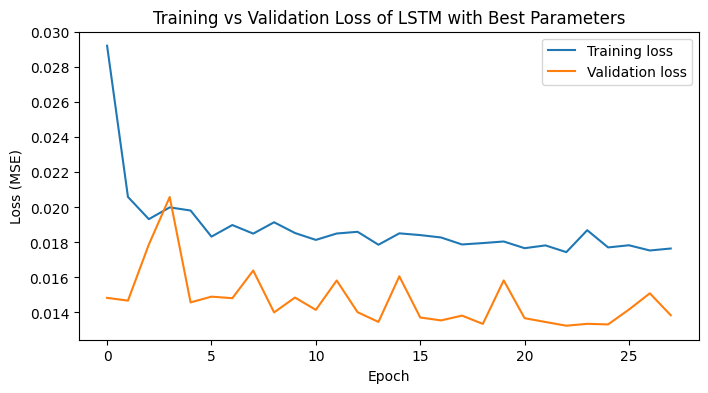

In [84]:
plt.figure(figsize=(8,4))
plt.plot(history_best.history['loss'], label='Training loss')
plt.plot(history_best.history['val_loss'], label='Validation loss')
plt.title("Training vs Validation Loss of LSTM with Best Parameters")
plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.legend()
plt.show()

In [85]:
predict_best=model_best.predict(X_test)

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step 


In [34]:
y_pred_best = scaler.inverse_transform(np.hstack((predict_best, X_test[:, -1, 1:])))[:,9]


In [87]:
y_pred_best_2=scaler_y.inverse_transform(predict_best)

### Plot

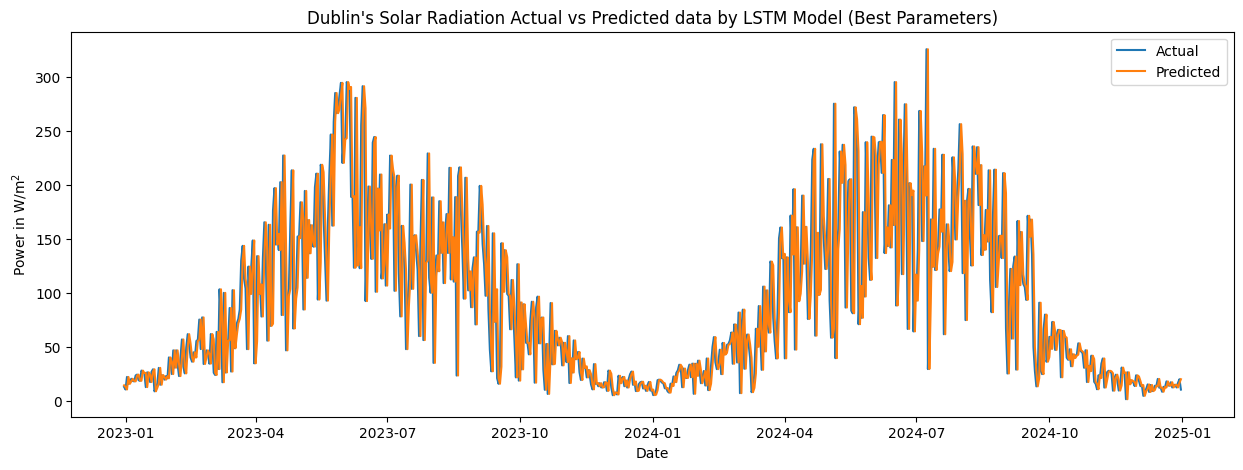

In [39]:
plt.figure(figsize=(15,5))
plt.plot(test['solarradiation'], label="Actual")
plt.plot(test.index,y_pred_best, label="Predicted")
plt.legend()
plt.xlabel('Date')
plt.ylabel('Power in W/m$^2$')
plt.title("Dublin's Solar Radiation Actual vs Predicted data by LSTM Model (Best Parameters)")
plt.show()


In [88]:
# Compute accuracy metrics
rmse = np.sqrt(mean_squared_error(test['solarradiation'], y_pred_best_2))
mae = mean_absolute_error(test['solarradiation'], y_pred_best_2)
r2 = r2_score(test['solarradiation'], y_pred_best_2)
mape=mean_absolute_percentage_error(test['solarradiation'], y_pred_best_2)

print(f"RMSE: {rmse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"R² Score: {r2:.4f}")
print(f'MAPE: {mape:.4f}')

RMSE: 42.3228
MAE: 30.4531
R² Score: 0.6784
MAPE: 0.5945


In [40]:
# Compute accuracy metrics
rmse = np.sqrt(mean_squared_error(test['solarradiation'], y_pred_best))
mae = mean_absolute_error(test['solarradiation'], y_pred_best)
r2 = r2_score(test['solarradiation'], y_pred_best)
mape=mean_absolute_percentage_error(test['solarradiation'], y_pred_best)

print(f"RMSE: {rmse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"R² Score: {r2:.4f}")
print(f'MAPE: {mape:.4f}')

RMSE: 54.4403
MAE: 36.1265
R² Score: 0.4679
MAPE: 0.5604


In [41]:
# Symmetric Mean Absolute Percentae Error Function
def smape(test, pred):
    test, pred = np.array(test), np.array(pred)
    return 100 * np.mean(2 * np.abs(pred - test) /
                         (np.abs(test) + np.abs(pred) + 1e-8))

print("SMAPE:", smape(test['solarradiation'], y_pred_best))

SMAPE: 42.03935927899308


## Fine Tune by Random Search

### Build the model

In [698]:
def build_model(hp: kt.HyperParameters):
    model = Sequential()
    
    model.add(LSTM(
        units=hp.Int('lstm_units', min_value=32, max_value=256, step=32),
        dropout=hp.Choice("dropout", values=[0.0, 0.1, 0.2, 0.3, 0.5]),
        recurrent_dropout=hp.Choice("recurrent_dropout", values=[0.0, 0.1, 0.2]),
        return_sequences=False,
        input_shape=(lookback, X_train.shape[2]),
    ))

    # Dense 
    if hp.Boolean("add_dense", default=False):
        model.add(Dense(hp.Choice("dense_units", [16, 32, 64]), activation="relu"))

    # Output
    model.add(Dense(1))

    # Optimizer 
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=hp.Choice("lr", values=[.0001, .0003, .001, .003]) ),
                  loss="mse",
                  metrics=["mae"],
                 )
    return model


In [699]:
tuner = kt.RandomSearch(
    build_model,
    objective="val_mae",
    max_trials=10,
    directory="lstm_params",
    project_name="lstm_best_params",
    overwrite=True,
)

C:\Users\erick\anaconda3\envs\ca1\Lib\site-packages\keras\src\layers\rnn\rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [708]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_mae", patience=5, restore_best_weights=True)

In [701]:
tuner.search(
    X_train, y_train,
    validation_split=0.2,
    epochs=100,                         
    batch_size=32,                          
    callbacks=[early_stop],
    shuffle=False,                                   
    verbose=1,
)

Trial 10 Complete [00h 00m 20s]
val_mae: 0.13203272223472595

Best val_mae So Far: 0.08440510183572769
Total elapsed time: 00h 04m 23s


In [90]:
best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]
print(best_hp.values)

NameError: name 'tuner' is not defined

In [89]:
final_model = tuner.hypermodel.build(best_hp)

NameError: name 'tuner' is not defined

In [704]:
final_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                        │ (None, 96)                  │          41,088 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 32)                  │           3,104 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 44,225 (172.75 KB)

 Trainable params: 44,225 (172.75 KB)

 Non-trainable params: 0 (0.00 B)

In [709]:
history_fm= final_model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0153 - mae: 0.0906 - val_loss: 0.0125 - val_mae: 0.0803
Epoch 2/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0160 - mae: 0.0930 - val_loss: 0.0129 - val_mae: 0.0813
Epoch 3/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0155 - mae: 0.0902 - val_loss: 0.0135 - val_mae: 0.0821
Epoch 4/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0149 - mae: 0.0885 - val_loss: 0.0129 - val_mae: 0.0814
Epoch 5/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0147 - mae: 0.0880 - val_loss: 0.0134 - val_mae: 0.0883
Epoch 6/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0153 - mae: 0.0910 - val_loss: 0.0127 - val_mae: 0.0801
Epoch 7/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0153 - mae: 0.0892 - val_loss: 0.0160 - val_mae: 0.0986
Epoch 8/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0151 - mae: 0.0923 - val_loss: 0.0136 - val_mae: 0.0848
Epoch 9/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.01

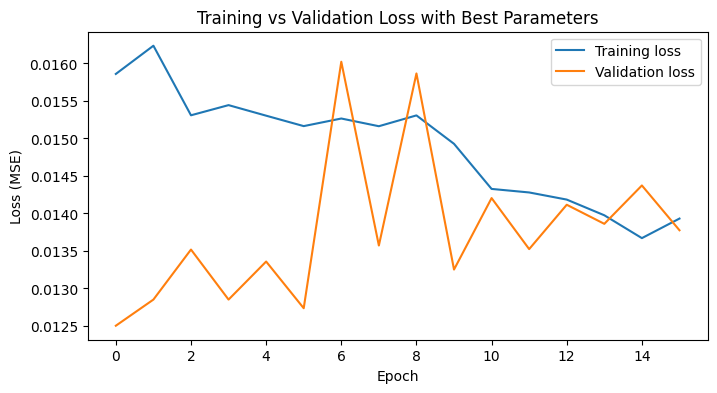

In [710]:
plt.figure(figsize=(8,4))
plt.plot(history_fm.history['loss'], label='Training loss')
plt.plot(history_fm.history['val_loss'], label='Validation loss')
plt.title("Training vs Validation Loss with Best Parameters")
plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.legend()
plt.show()

In [711]:
predict_fm=final_model.predict(X_test)

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step 


In [712]:
y_pred_fm = scaler.inverse_transform(np.hstack((predict_fm, X_test[:, -1, 1:])))[:,9]


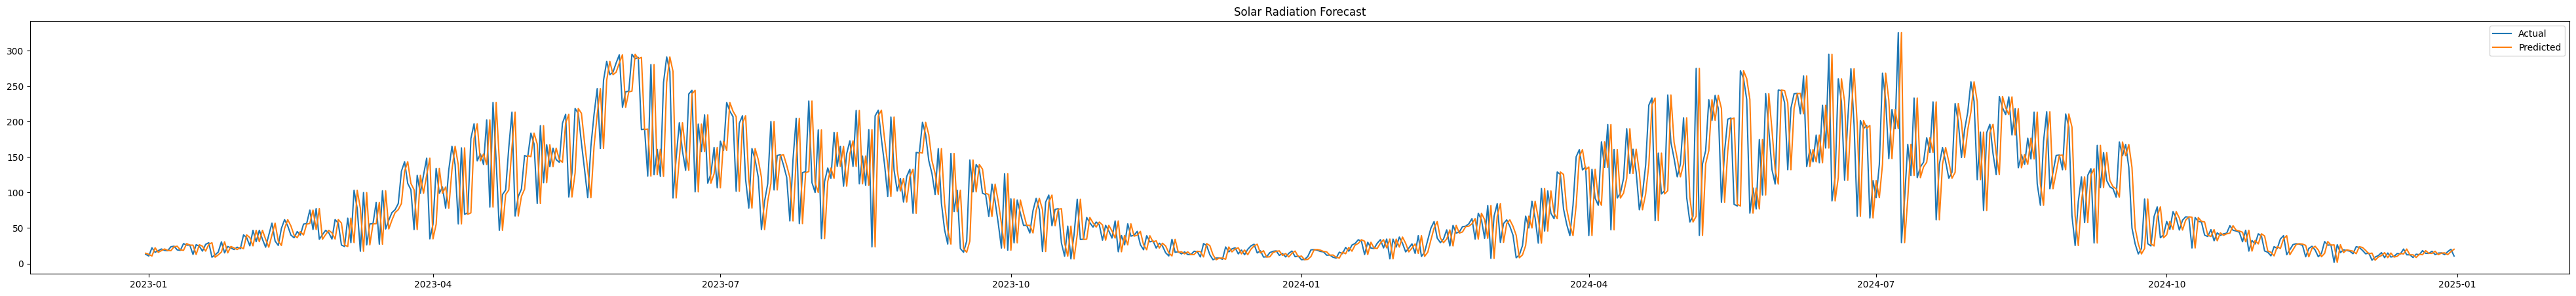

In [713]:
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, r2_score

plt.figure(figsize=(50,5))
plt.plot(test['solarradiation'], label="Actual")
plt.plot(test.index,y_pred_fm, label="Predicted")
plt.legend()
plt.title("Solar Radiation Forecast")
plt.show()


In [714]:
# Compute accuracy metrics
rmse = np.sqrt(mean_squared_error(test['solarradiation'], y_pred_fm))
mae = mean_absolute_error(test['solarradiation'], y_pred_fm)
r2 = r2_score(test['solarradiation'], y_pred_fm)
mape=mean_absolute_percentage_error(test['solarradiation'], y_pred_fm)

print(f"RMSE: {rmse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"R² Score: {r2:.4f}")
print(f'MAPE: {mape:.4f}')

RMSE: 54.4403
MAE: 36.1265
R² Score: 0.4679
MAPE: 0.5604


In [715]:
# Symmetric Mean Absolute Percentae Error Function
def smape(test, pred):
    test, pred = np.array(test), np.array(pred)
    return 100 * np.mean(2 * np.abs(pred - test) /
                         (np.abs(test) + np.abs(pred) + 1e-8))

print("SMAPE:", smape(test['solarradiation'], y_pred_fm))

SMAPE: 42.03935927899308


## KerasTuner Bayesian Optimization

In [161]:
#  model function for BayesianOptimization 
def build_model(hp: kt.HyperParameters):
    # grid search range
    units1   = hp.Int("units1", min_value=32, max_value=256, step=32)
    second_layer = hp.Boolean("use_second_lstm") # add other layer
    units2   = hp.Int("units2", 32, 256, step=32) if second_layer else None
    dropout  = hp.Float("dropout", 0.0, 0.5, step=0.1)
    rdropout = hp.Float("recurrent_dropout", 0.0, 0.5, step=0.1)
    lr       = hp.Choice("lr", [0.001, 0.0005, 0.0001])

    model = Sequential()
    # first LSTM
    model.add(LSTM(units1,
               input_shape=(lookback, 10), #30 days , 10 features
               return_sequences=second_layer,   # sequences 
               dropout=dropout,
               recurrent_dropout=rdropout))
    # second LSTM layer
    if second_layer:
        m.add(LSTM(units2,
                   return_sequences=False,
                   dropout=dropout,
                   recurrent_dropout=rdropout))
    # output dense
    model.add(Dense(1))

    model.compile(optimizer=Adam(learning_rate=lr),loss="mse", metrics=["mae"])
    return model

In [158]:
#  Bayesian optimization
tuner = kt.BayesianOptimization(
    build_model,
    objective="val_loss",          # minimize validation loss
    max_trials=10,                 # total models to do
    num_initial_points=5,          # random 
    overwrite=True,
    directory="kt_logs",        #save parameters
    project_name="lstm_bayes"
)

In [94]:
# early stopping
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True)
#reduce learning rate if validation loss stalls
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.5, patience=5, min_lr=0.000006)
# save the best parameters
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "best_lstm.h5", save_best_only=True, monitor="val_loss")



In [162]:
# search 
tuner.search(
    X_train, y_train,
    validation_split=0.2,     
    epochs=100,
    batch_size=kt.HyperParameters().Choice("batch_size", [16, 32, 64]),
    shuffle=False,            
    callbacks=[early_stop, reduce_lr, checkpoint],
    verbose=1
)




Trial 4 Complete [00h 00m 01s]

Best val_loss So Far: 0.0147353271022439
Total elapsed time: 00h 01m 55s

Search: Running Trial #5

Value             |Best Value So Far |Hyperparameter
96                |256               |units1
False             |False             |use_second_lstm
0.2               |0                 |dropout
0.2               |0.3               |recurrent_dropout
0.0005            |0.0005            |lr
160               |128               |units2

Epoch 1/100
144/145 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0901 - mae: 0.2460

145/145 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - loss: 0.0897 - mae: 0.2453 - val_loss: 0.0207 - val_mae: 0.1063 - learning_rate: 5.0000e-04
Epoch 2/100
144/145 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0450 - mae: 0.1689

145/145 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 0.0450 - mae: 0.1687 - val_loss: 0.0201 - val_mae: 0.1065 - learning_rate: 5.0000e-04
Epoch 3/100
143/145 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0430 - mae: 0.1661

145/145 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 0.0429 - mae: 0.1659 - val_loss: 0.0192 - val_mae: 0.1070 - learning_rate: 5.0000e-04
Epoch 4/100
140/145 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0333 - mae: 0.1456

145/145 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - loss: 0.0333 - mae: 0.1455 - val_loss: 0.0187 - val_mae: 0.1064 - learning_rate: 5.0000e-04
Epoch 5/100
142/145 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0365 - mae: 0.1515

145/145 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - loss: 0.0364 - mae: 0.1513 - val_loss: 0.0186 - val_mae: 0.1044 - learning_rate: 5.0000e-04
Epoch 6/100
 97/145 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0397 - mae: 0.1558

KeyboardInterrupt: 

Print best Parameters

In [720]:
best_hp = tuner.get_best_hyperparameters(1)[0]
print("Best HP:", best_hp.values)

Best HP: {'units1': 128, 'use_second_lstm': False, 'dropout': 0.0, 'recurrent_dropout': 0.2, 'lr': 0.001, 'units2': 128}


Model Using Best Parameters 

In [96]:
best_model = Sequential([
    LSTM(128,recurrent_dropout=0.2, input_shape=(lookback, X_train.shape[2])),
    Dropout(0.0),
    Dense(horizon)
])

best_model.compile(optimizer=Adam(learning_rate=0.001), loss='mse')
best_model.summary()

Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm_34 (LSTM)                       │ (None, 128)                 │          71,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_34 (Dropout)                 │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_10 (Dense)                     │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 71,297 (278.50 KB)

 Trainable params: 71,297 (278.50 KB)

 Non-trainable params: 0 (0.00 B)

In [163]:
best_model = tuner.get_best_models(1)[0]
best_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 256)                 │         273,408 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 1)                   │             257 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 273,665 (1.04 MB)

 Trainable params: 273,665 (1.04 MB)

 Non-trainable params: 0 (0.00 B)

In [97]:
history_best= best_model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - loss: 0.0491 - val_loss: 0.0176
Epoch 2/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0207 - val_loss: 0.0154
Epoch 3/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0197 - val_loss: 0.0144
Epoch 4/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0194 - val_loss: 0.0144
Epoch 5/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0194 - val_loss: 0.0147
Epoch 6/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0190 - val_loss: 0.0155
Epoch 7/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0189 - val_loss: 0.0143
Epoch 8/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0183 - val_loss: 0.0141
Epoch 9/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0174 - val_loss: 0.0143
Epoch 10/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0180 - val_loss: 0.0139
Epoch 11/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0186 - val_loss: 0.0139
Epoch 12/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step

### Train and validation plot

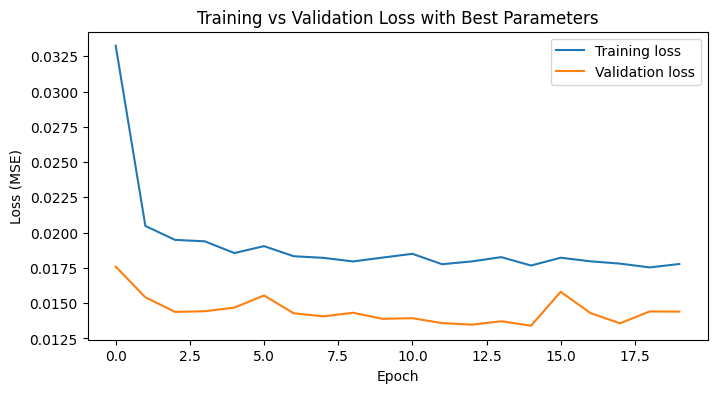

In [98]:
plt.figure(figsize=(8,4))
plt.plot(history_best.history['loss'], label='Training loss')
plt.plot(history_best.history['val_loss'], label='Validation loss')
plt.title("Training vs Validation Loss with Best Parameters")
plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.legend()
plt.show()

### Predict

In [104]:
from keras.models import load_model
# Load the trained LSTM model
model = load_model('lstm_tuning/best_lstm.h5', custom_objects={'mse': 'MeanSquaredError'})


In [105]:
predict_fm=model.predict(X_test)

23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step 


In [178]:
y_pred_fm = scaler.inverse_transform(np.hstack((predict_fm, X_test[:, -1, 1:])))[:,9]


In [106]:
y_pred_fm_2=scaler_y.inverse_transform(predict_fm)

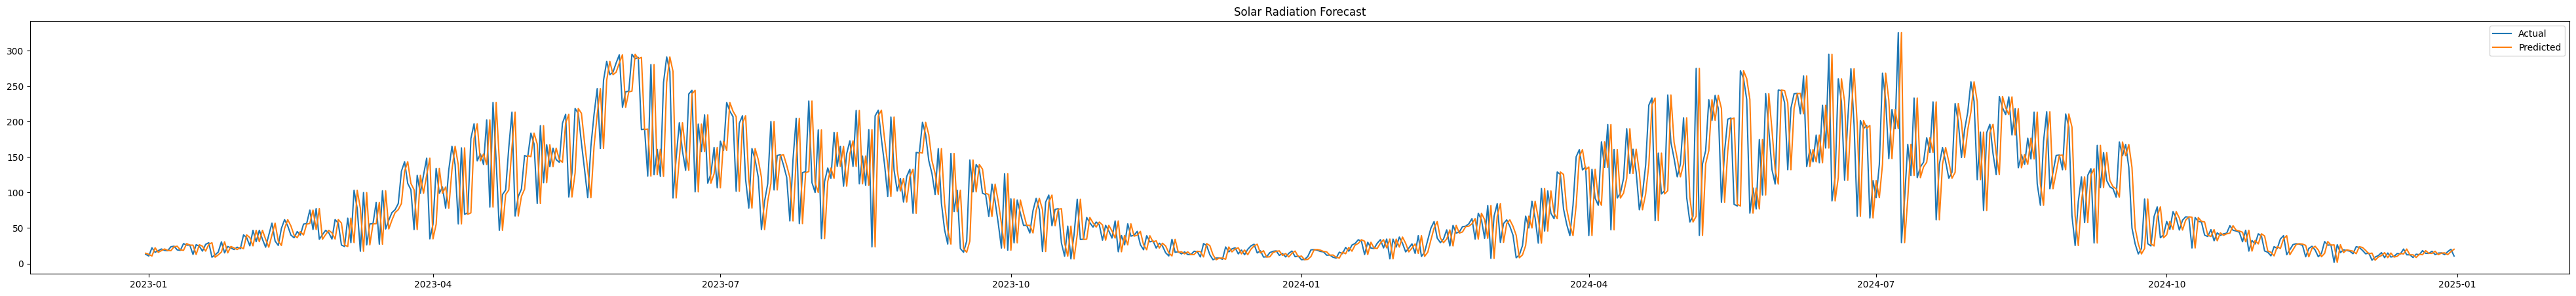

In [726]:
plt.figure(figsize=(50,5))
plt.plot(test['solarradiation'], label="Actual")
plt.plot(test.index,y_pred_fm, label="Predicted")
plt.legend()
plt.title("Solar Radiation Forecast")
plt.show()


In [107]:
# Compute accuracy metrics
rmse = np.sqrt(mean_squared_error(test['solarradiation'], y_pred_fm_2))
mae = mean_absolute_error(test['solarradiation'], y_pred_fm_2)
r2 = r2_score(test['solarradiation'], y_pred_fm_2)
mape=mean_absolute_percentage_error(test['solarradiation'], y_pred_fm_2)

print(f"RMSE: {rmse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"R² Score: {r2:.4f}")
print(f'MAPE: {mape:.4f}')

RMSE: 47.2686
MAE: 36.9101
R² Score: 0.5989
MAPE: 0.8819


In [727]:
# Compute accuracy metrics
rmse = np.sqrt(mean_squared_error(test['solarradiation'], y_pred_fm))
mae = mean_absolute_error(test['solarradiation'], y_pred_fm)
r2 = r2_score(test['solarradiation'], y_pred_fm)
mape=mean_absolute_percentage_error(test['solarradiation'], y_pred_fm)

print(f"RMSE: {rmse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"R² Score: {r2:.4f}")
print(f'MAPE: {mape:.4f}')

RMSE: 54.4403
MAE: 36.1265
R² Score: 0.4679
MAPE: 0.5604


In [728]:
# Symmetric Mean Absolute Percentae Error Function
def smape(test, pred):
    test, pred = np.array(test), np.array(pred)
    return 100 * np.mean(2 * np.abs(pred - test) /
                         (np.abs(test) + np.abs(pred) + 1e-8))

print("SMAPE:", smape(test['solarradiation'], y_pred_fm))

SMAPE: 42.03935927899308


### Residuals

In [110]:
y_pred_fm_2.shape

(732, 1)

In [113]:
y=test['solarradiation']
yhat=y_pred_fm
residuals = y - yhat
sns.scatterplot(x=y, y=yhat)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Actual Solar Radiation data")
plt.ylabel("Residual")
plt.title("Residuals vs Actual Values (LSTM Model)")

NameError: name 'y_pred_fm' is not defined

# Experiment 2:

To develop a LSTM Model applying **differencing** to the target feature.

**Differencing** in time series is a technique used to remove trends or seasonal effects by calculating the difference between consecutive observations. This helps to stabilize the mean of the time series and make it stationary, which is important for accurate forecasting.

### Load the Data

In [115]:
df = pd.read_csv("Datasets/dublin_2015_to_2024_final.csv", parse_dates=["datetime"])
df = df.sort_index()


- parse_dates = ["datetime"] the time order is explicit
- sort_index() is to avoid shuffling 

### Differencing technique

In [116]:
df['solarradiation_diff'] = df['solarradiation'].diff(1)

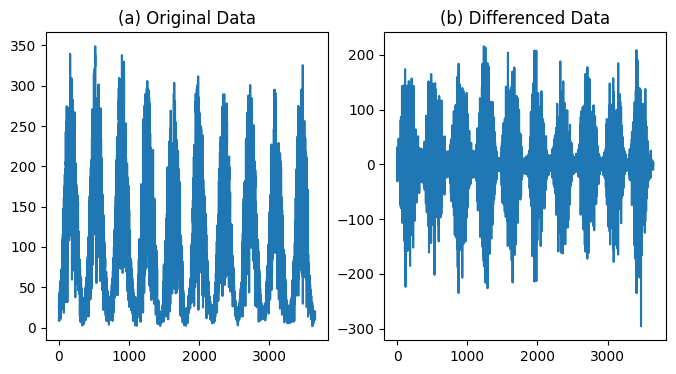

In [117]:
plt.figure(figsize=(8,4))
plt.subplot(1, 2, 1)
plt.plot(df['solarradiation'])
plt.title("(a) Original Data")

plt.subplot(1, 2, 2)
plt.plot(df['solarradiation_diff'])
plt.title("(b) Differenced Data")
plt.show()

## Split data into Train(8 years) and Test(2 years)

The dataset was devided into train and test, with the purpuse of having real data for comparing model's prediction data

In [118]:
train = df[df['datetime'] < '2022-12-31']
test = df[df['datetime'] >= '2022-12-31'].copy()

In [119]:
train=train.drop('solarradiation',axis=1)
train = train.dropna()

In [120]:
test=test.drop('solarradiation',axis=1)
test= test.dropna()

set index

In [121]:
train.set_index("datetime", inplace=True)
test.set_index("datetime", inplace=True)


In [736]:
train.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2920 entries, 2015-01-02 to 2022-12-30
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   tempmax              2920 non-null   float64
 1   humidity             2920 non-null   float64
 2   precip               2920 non-null   float64
 3   windgust             2920 non-null   float64
 4   windspeed            2920 non-null   float64
 5   winddir              2920 non-null   float64
 6   sealevelpressure     2920 non-null   float64
 7   cloudcover           2920 non-null   float64
 8   visibility           2920 non-null   float64
 9   solarradiation_diff  2920 non-null   float64
dtypes: float64(10)
memory usage: 250.9 KB


Note:

column 9 is the target feature

In [737]:
test.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 732 entries, 2022-12-31 to 2024-12-31
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   tempmax              732 non-null    float64
 1   humidity             732 non-null    float64
 2   precip               732 non-null    float64
 3   windgust             732 non-null    float64
 4   windspeed            732 non-null    float64
 5   winddir              732 non-null    float64
 6   sealevelpressure     732 non-null    float64
 7   cloudcover           732 non-null    float64
 8   visibility           732 non-null    float64
 9   solarradiation_diff  732 non-null    float64
dtypes: float64(10)
memory usage: 62.9 KB


## Scaling

MinMaxScaler scale the data into a range or 0-1

In [122]:
scaler = MinMaxScaler()

train_scaled = scaler.fit_transform(train)
test_scaled= scaler.fit_transform(test)

## Make sequences

The create_sequence() function below divide the sequence into input/output patterns called samples, where lookback are the time steps used as input and horizon is the prediction

In [123]:
lookback = 30 # 30 days in memory
horizon = 1 # predicts next day

In [124]:
def create_sequences(data, lookback, horizon):
    X, y = [], []
    
    for i in range(lookback, len(data)- horizon+1):
        X.append(data[i-lookback:i,:])
        y.append(data[i + horizon-1, 9])  # 9 is Solarradiation_diff feature
    return np.array(X), np.array(y)


- lookbak = how much past information is in memory
- horizon = how far ahead is predicting (1 predicts next day)

## X_train and y_train

computing create_sequences() function to create samples from train_scaled dataset

In [125]:
#Build train sequences from train_scaled

X_train, y_train = create_sequences(train_scaled, lookback, horizon)

In [126]:

X_train.shape

(2890, 30, 10)

In [127]:
y_train.shape

(2890,)

## History for test

test need some history, the last lookback rows are concatenated at the beginning of test

In [128]:
history = train_scaled[-lookback:,:]
test_history= np.vstack([history, test_scaled])

In [129]:
test_history.shape

(762, 10)

## create X_test, y_test

In [130]:
X_test, y_test = create_sequences(test_history, lookback, horizon)

In [131]:
X_test.shape,y_test.shape

((732, 30, 10), (732,))

## Build the  LSTM Model

The first layer that is added is an LSTM layer. The LSTM class accept several parameters:

- units, the number of LSTM neurons that are included in this layer
- return_sequences = True, this indicates that another LSTM layer will be added after the current layer already added.
- intup_shape, the number of timesteps and the number of predictors in out trainign data. Predictor is 1 ('solarradiation')

**Dropout regularization** is a technique used to avoid overfitting when training neural networks.
It involves randomly excluding or dropping out certain layer outputs during the training stage.
The dropout rate indicates how many neurons should be dropped in a specific layer of the neural network.

**Output Layer**, the Dense class will be the output layer. The parameter that has to be specified is units, which is the desired number of dimentions that the output layer should generate. 

TensorFlows allows to compile a nueral network, it accepts two arguments: optimizer and loss.

The Adam optimizer is useful in a wide variety of neural networks architectures.
The loss parameter is mean squared error, this is to measure the performance.

In [132]:
model = Sequential([
    LSTM( 64,return_sequences=True, input_shape=(lookback, X_train.shape[2])),
    Dropout(0.2),
    #Dense(horizon)
])
model.add(LSTM(units = 64, return_sequences = True))

model.add(Dropout(0.2))

model.add(LSTM(units = 64, return_sequences = True))

model.add(Dropout(0.2))

model.add(LSTM(units = 64))

model.add(Dropout(0.2))
model.add(Dense(units=1))
model.compile(optimizer='adam', loss='mse')
model.summary()

Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm_35 (LSTM)                       │ (None, 30, 64)              │          19,200 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_35 (Dropout)                 │ (None, 30, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_36 (LSTM)                       │ (None, 30, 64)              │          33,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_36 (Dropout)                 │ (None, 30, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_37 (LSTM)                       │ (None, 30, 64)              │          33,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_37 (Dropout)                 │ (None, 30, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_38 (LSTM)                       │ (None, 64)                  │          33,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_38 (Dropout)                 │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_11 (Dense)                     │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 118,337 (462.25 KB)

 Trainable params: 118,337 (462.25 KB)

 Non-trainable params: 0 (0.00 B)

## Training the Model

**EarlyStopping**

Stop training when a monitored metric has stopped improving. Assuming the goal of a training is to minimize the loss. 

In [133]:
es = EarlyStopping(monitor='val_loss', mode='min', verbose=1, patience=5)


The LSTM model is trained with X_train and y_train dataframes, 20% of the train data is been use as 'validation data'. This helps keras to evaluate loss on a separete dataset

In [134]:
history = model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=500,
    batch_size=32,
    callbacks=[es],
    shuffle=False,
    verbose=1
)


Epoch 1/500
73/73 ━━━━━━━━━━━━━━━━━━━━ 8s 37ms/step - loss: 0.0350 - val_loss: 0.0152
Epoch 2/500
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - loss: 0.0199 - val_loss: 0.0124
Epoch 3/500
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - loss: 0.0192 - val_loss: 0.0122
Epoch 4/500
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - loss: 0.0185 - val_loss: 0.0120
Epoch 5/500
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - loss: 0.0180 - val_loss: 0.0120
Epoch 6/500
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - loss: 0.0179 - val_loss: 0.0120
Epoch 7/500
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - loss: 0.0179 - val_loss: 0.0121
Epoch 8/500
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - loss: 0.0175 - val_loss: 0.0120
Epoch 9/500
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - loss: 0.0177 - val_loss: 0.0122
Epoch 10/500
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - loss: 0.0180 - val_loss: 0.0121
Epoch 11/500
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - loss: 0.0176 - val_loss: 0.0122
Epoch 12/500
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step

## Loss Plot

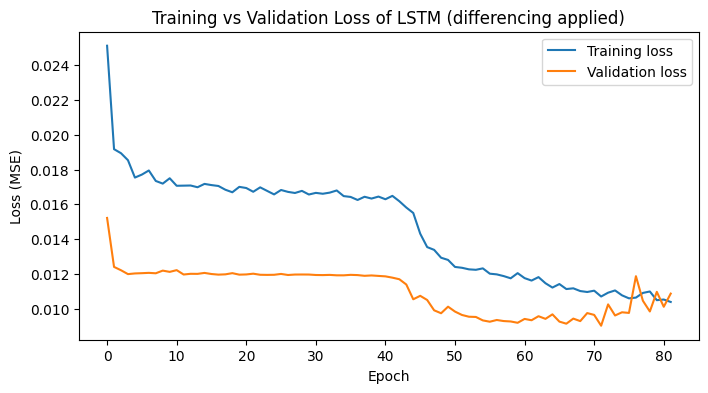

In [135]:
plt.figure(figsize=(8,4))
plt.plot(history.history['loss'], label='Training loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.title("Training vs Validation Loss of LSTM (differencing applied)")
plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.legend()
plt.show()

Observations:
- Validation and training loss decrase and flat
- Loss is stable
- no overfitting

## Predict

In [136]:
y_pred = model.predict(X_test)


23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step 


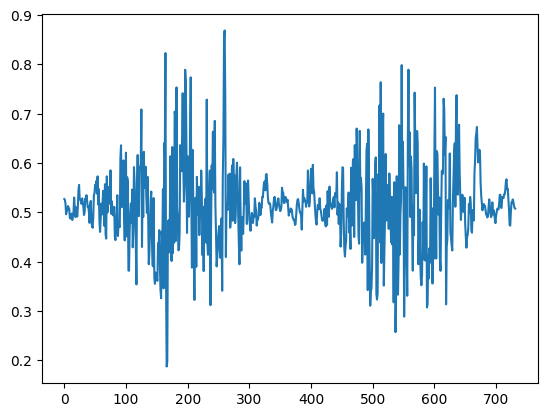

In [137]:
plt.plot(y_pred)

## Unscale

In [263]:
#y_test_inv = scaler.inverse_transform(np.hstack((y_test.reshape(-1,1), #target 
#                                                X_test[:, -1, 1:] # exogenous data last step
#                                                )))[:,9] #take only the solarradiation units


In [66]:
y_pred_inv = scaler.inverse_transform(np.hstack((y_pred, #predictions
                                                 X_test[:, -1, 1:]
                                                )))[:,9] # solarradiation feature


In [156]:
y_pred_inv=scaler_y.inverse_transform(y_pred.reshape(-1,1))

### Undo log transformation

In [155]:
train = df[df['datetime'] < '2022-12-31']

In [158]:
# last actual value before test starts
last_train_value = train['solarradiation'].iloc[-1]

# make into a Series to handle cumulative sum easily
y_pred_diff = pd.Series(y_pred_inv[0])

# reconstruct original scale
y_pred_original = last_train_value + np.cumsum(y_pred_diff)


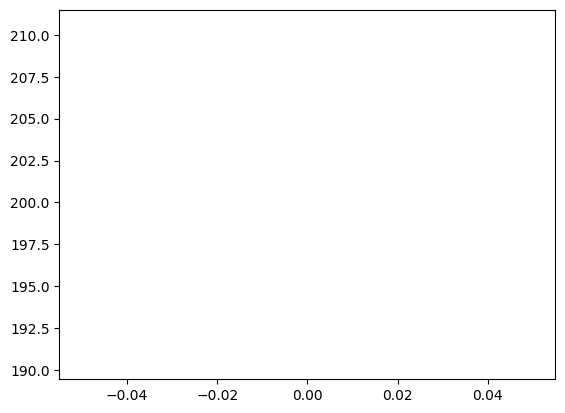

In [159]:
plt.plot(y_pred_original)

## Actual vs Predicted Data Plot

In [145]:
test_org = df[df['datetime'] >= '2022-12-31'].copy()

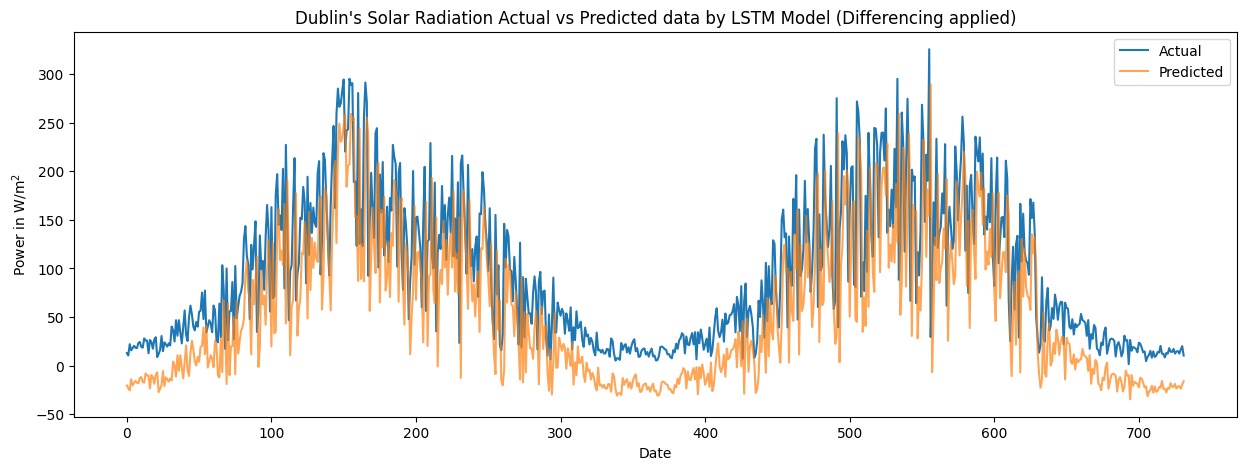

In [72]:
plt.figure(figsize=(15,5))
plt.plot(test_org['solarradiation'].values, label='Actual')
plt.plot(y_pred_original, label='Predicted', alpha=0.7)
plt.legend()
plt.xlabel('Date')
plt.ylabel('Power in W/m$^2$')
plt.title("Dublin's Solar Radiation Actual vs Predicted data by LSTM Model (Differencing applied)")

plt.show()


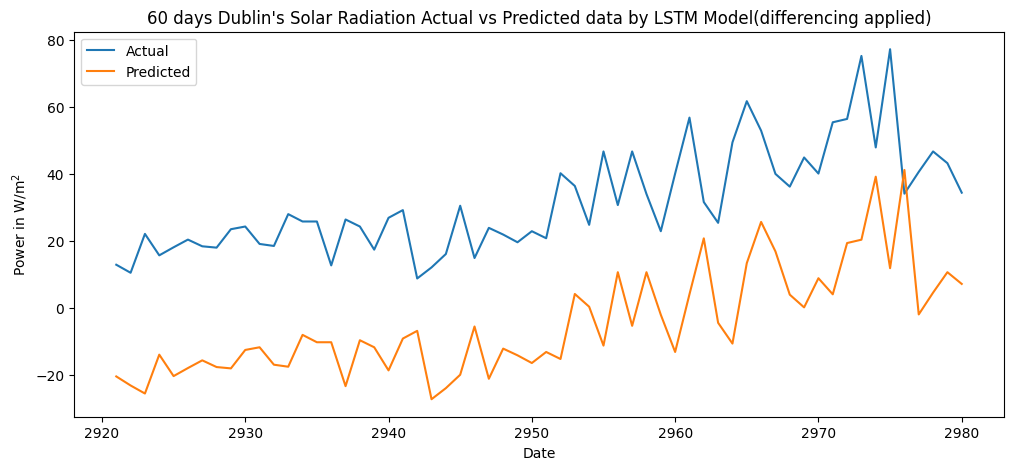

In [77]:
plt.figure(figsize=(12,5))
t=test_org['solarradiation']
plt.plot(test_org.index[:60],t[:60], label="Actual")
plt.plot(test_org.index[:60],y_pred_original[:60], label="Predicted")
plt.legend()
plt.title("Predicted vs Actual (Test Set)")
plt.xlabel('Date')
plt.ylabel('Power in W/m$^2$')
plt.title("60 days Dublin's Solar Radiation Actual vs Predicted data by LSTM Model(differencing applied)")
plt.show()

## Accuracy

In [146]:
# Compute accuracy metrics
rmse = np.sqrt(mean_squared_error(test_org['solarradiation'], y_pred_original))
mae = mean_absolute_error(test_org['solarradiation'], y_pred_original)
r2 = r2_score(test_org['solarradiation'], y_pred_original)
mape=mean_absolute_percentage_error(test_org['solarradiation'], y_pred_original)

print(f"RMSE: {rmse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"R² Score: {r2:.4f}")
print(f'MAPE: {mape:.4f}')

ValueError: Found input variables with inconsistent numbers of samples: [732, 1]

In [78]:
# Compute accuracy metrics
rmse = np.sqrt(mean_squared_error(test_org['solarradiation'], y_pred_original))
mae = mean_absolute_error(test_org['solarradiation'], y_pred_original)
r2 = r2_score(test_org['solarradiation'], y_pred_original)
mape=mean_absolute_percentage_error(test_org['solarradiation'], y_pred_original)

print(f"RMSE: {rmse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"R² Score: {r2:.4f}")
print(f'MAPE: {mape:.4f}')

RMSE: 65.2781
MAE: 51.5993
R² Score: 0.2350
MAPE: 1.0354


### Correcting data

In [770]:
#get arrays
y_true = np.asarray(test['solarradiation']).ravel()
y_pred = np.asarray(y_pred_original).ravel()

In [771]:
#Fit linear correction: y_true ≈ a * y_pred + b
lr = LinearRegression()
lr.fit(y_pred.reshape(-1, 1), y_true)
a, b = lr.coef_[0], lr.intercept_

In [772]:
# Apply correction 
y_pred_corrected = a * y_pred + b
y_pred_corrected = np.clip(y_pred_corrected, 0, None)

In [773]:
print(f"a (scale): {a:.4f}, b (bias): {b:.4f}")


a (scale): 0.7340, b (bias): 51.2220


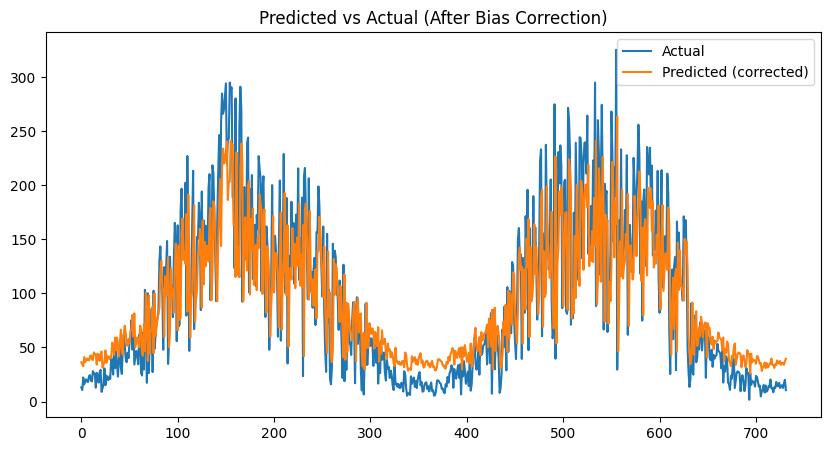

In [778]:
plt.figure(figsize=(10,5))
plt.plot(test['solarradiation'].values, label='Actual')
plt.plot(y_pred_corrected, label='Predicted (corrected)')
plt.legend()
plt.title('Predicted vs Actual (After Bias Correction)')
plt.show()

## Accuracy

In [779]:
# Compute accuracy metrics
rmse = np.sqrt(mean_squared_error(test['solarradiation'], y_pred_corrected))
mae = mean_absolute_error(test['solarradiation'], y_pred_corrected)
r2 = r2_score(test['solarradiation'], y_pred_corrected)
mape=mean_absolute_percentage_error(test['solarradiation'], y_pred_corrected)

print(f"RMSE: {rmse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"R² Score: {r2:.4f}")
print(f'MAPE: {mape:.4f}')

RMSE: 50.6926
MAE: 37.3644
R² Score: 0.5387
MAPE: 0.8183


In [776]:
# Symmetric Mean Absolute Percentae Error Function
def smape(test, pred):
    test, pred = np.array(test), np.array(pred)
    return 100 * np.mean(2 * np.abs(pred - test) /
                         (np.abs(test) + np.abs(pred) + 1e-8))

print("SMAPE:", smape(test['solarradiation'], y_pred_corrected))

SMAPE: 49.15164847485052


## KerasTuner Bayesian Optimization

In [80]:
#  model function for BayesianOptimization 
def build_model(hp: kt.HyperParameters) -> tf.keras.Model:
    # search space
    units1   = hp.Int("units1", min_value=32, max_value=256, step=32)
    second_layer = hp.Boolean("use_second_lstm") # add other layer
    units2   = hp.Int("units2", 32, 256, step=32) if second_layer else None
    dropout  = hp.Float("dropout", 0.0, 0.5, step=0.1)
    rdropout = hp.Float("recurrent_dropout", 0.0, 0.5, step=0.1)
    lr       = hp.Choice("lr", [0.001, 0.0005, 0.0001])

    model = Sequential()
    # first LSTM
    model.add(LSTM(units1,
               input_shape=(lookback, n_features),
               return_sequences=second_layer,   # sequences 
               dropout=dropout,
               recurrent_dropout=rdropout))
    # second LSTM layer
    if second_layer:
        m.add(LSTM(units2,
                   return_sequences=False,
                   dropout=dropout,
                   recurrent_dropout=rdropout))
    # output dense
    model.add(Dense(1))

    model.compile(optimizer=Adam(learning_rate=lr),loss="mse", metrics=["mae"])
    return model

In [81]:
#  Bayesian optimization
tuner = kt.BayesianOptimization(
    build_model,
    objective="val_loss",          # minimize validation loss
    max_trials=10,                 # total models to do
    num_initial_points=5,          # random 
    overwrite=True,
    directory="kt_logs",        #save parameters
    project_name="lstm_bayes"
)

In [82]:
# early stopping
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True)
#reduce learning rate if validation loss stalls
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.5, patience=5, min_lr=1e-6)
# save the best parameters
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "best_lstm.h5", save_best_only=True, monitor="val_loss")



In [83]:
# search 
tuner.search(
    X_train, y_train,
    validation_split=0.2,     
    epochs=100,
    batch_size=kt.HyperParameters().Choice("batch_size", [16, 32, 64]),
    shuffle=False,            
    callbacks=[early_stop, reduce_lr, checkpoint],
    verbose=1
)




Trial 10 Complete [00h 00m 01s]

Best val_loss So Far: 0.00869771558791399
Total elapsed time: 00h 07m 39s


Print best Parameters

In [84]:
best_hp = tuner.get_best_hyperparameters(1)[0]
print("Best HP:", best_hp.values)

Best HP: {'units1': 224, 'use_second_lstm': False, 'dropout': 0.1, 'recurrent_dropout': 0.30000000000000004, 'lr': 0.001, 'units2': 64}


Model Using Best Parameters 

In [85]:
best_model = tuner.get_best_models(1)[0]
best_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 224)                 │         210,560 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 1)                   │             225 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 210,785 (823.38 KB)

 Trainable params: 210,785 (823.38 KB)

 Non-trainable params: 0 (0.00 B)

In [86]:
history_best= best_model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/step - loss: 0.0118 - mae: 0.0802 - val_loss: 0.0092 - val_mae: 0.0708
Epoch 2/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - loss: 0.0119 - mae: 0.0796 - val_loss: 0.0089 - val_mae: 0.0685
Epoch 3/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - loss: 0.0115 - mae: 0.0784 - val_loss: 0.0092 - val_mae: 0.0694
Epoch 4/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - loss: 0.0121 - mae: 0.0819 - val_loss: 0.0090 - val_mae: 0.0679
Epoch 5/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - loss: 0.0115 - mae: 0.0787 - val_loss: 0.0091 - val_mae: 0.0692
Epoch 6/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - loss: 0.0121 - mae: 0.0812 - val_loss: 0.0090 - val_mae: 0.0689
Epoch 7/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - loss: 0.0118 - mae: 0.0799 - val_loss: 0.0090 - val_mae: 0.0686


### Train and validation plot

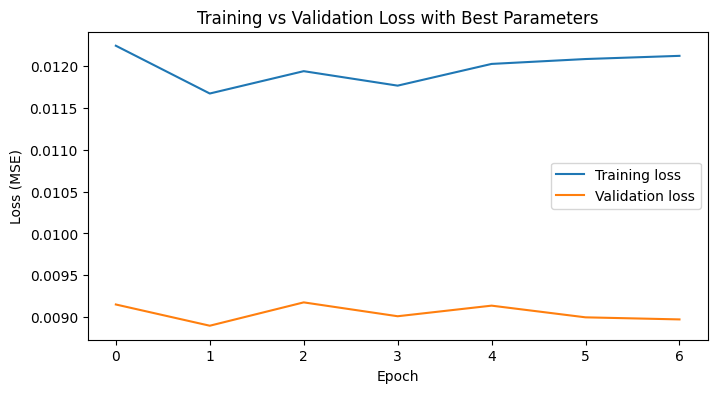

In [87]:
plt.figure(figsize=(8,4))
plt.plot(history_best.history['loss'], label='Training loss')
plt.plot(history_best.history['val_loss'], label='Validation loss')
plt.title("Training vs Validation Loss with Best Parameters")
plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.legend()
plt.show()

## Predict

In [88]:
y_pred = best_model.predict(X_test)


23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step 


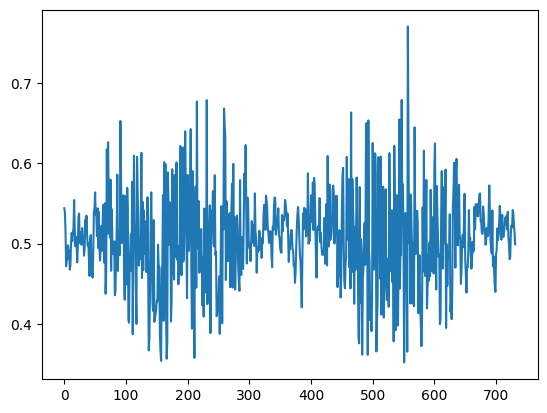

In [89]:
plt.plot(y_pred)

## Unscale

In [263]:
#y_test_inv = scaler.inverse_transform(np.hstack((y_test.reshape(-1,1), #target 
#                                                X_test[:, -1, 1:] # exogenous data last step
#                                                )))[:,9] #take only the solarradiation units


In [90]:
y_pred_inv = scaler.inverse_transform(np.hstack((y_pred, #predictions
                                                 X_test[:, -1, 1:]
                                                )))[:,9] # solarradiation feature


### Undo log transformation

In [91]:
train = df[df['datetime'] < '2022-12-31']

In [92]:
# last actual value before test starts
last_train_value = train['solarradiation'].iloc[-1]

# make into a Series to handle cumulative sum easily
y_pred_diff = pd.Series(y_pred_inv)

# reconstruct original scale
y_pred_original = last_train_value + np.cumsum(y_pred_diff)


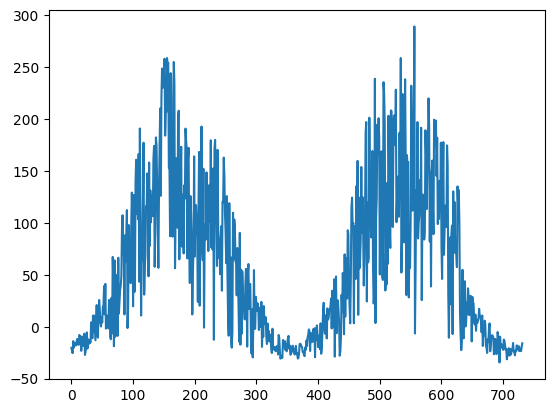

In [93]:
plt.plot(y_pred_original)

## Actual vs Predicted Data Plot

In [94]:
test_org = df[df['datetime'] >= '2022-12-31'].copy()

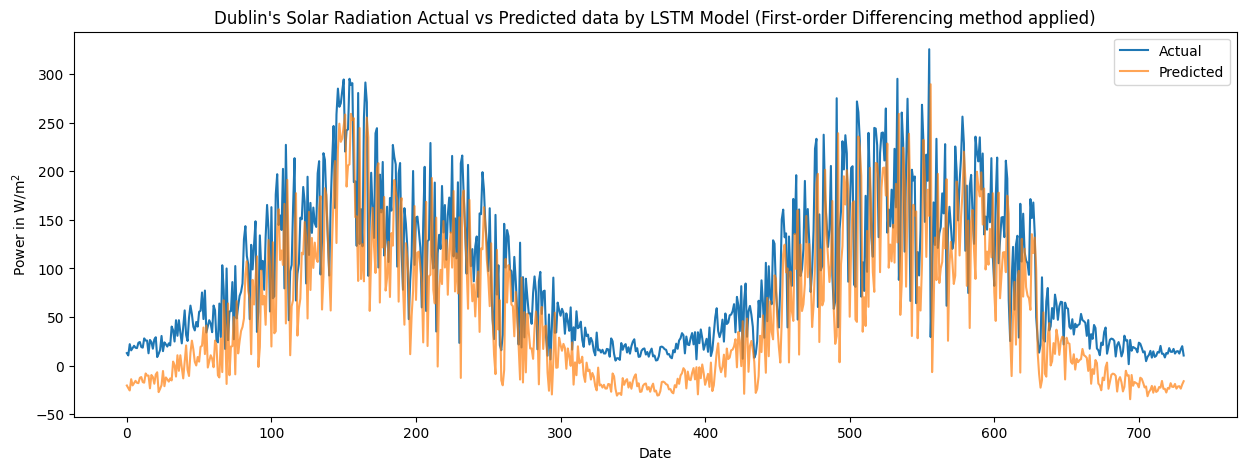

In [96]:
plt.figure(figsize=(15,5))
plt.plot(test_org['solarradiation'].values, label='Actual')
plt.plot(y_pred_original, label='Predicted', alpha=0.7)
plt.legend()
plt.xlabel('Date')
plt.ylabel('Power in W/m$^2$')
plt.title("Dublin's Solar Radiation Actual vs Predicted data by LSTM Model (First-order Differencing method applied)")

plt.show()


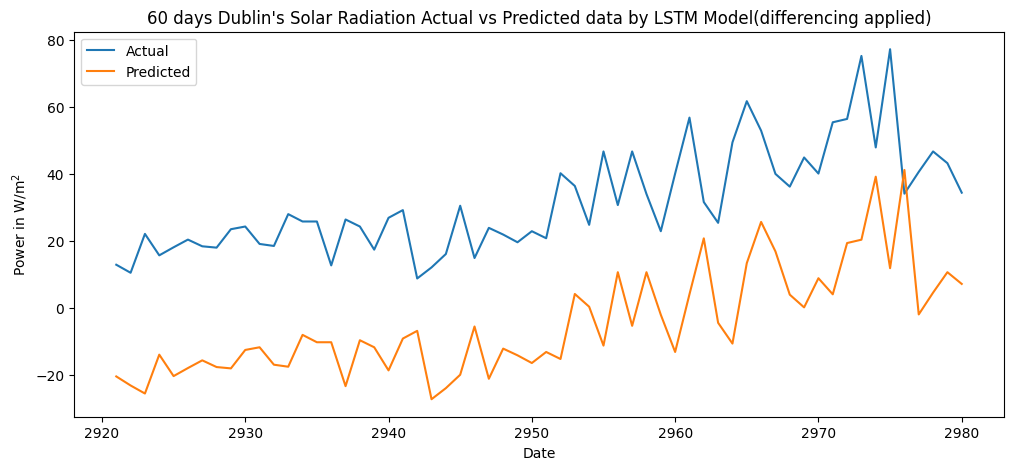

In [97]:
plt.figure(figsize=(12,5))
t=test_org['solarradiation']
plt.plot(test_org.index[:60],t[:60], label="Actual")
plt.plot(test_org.index[:60],y_pred_original[:60], label="Predicted")
plt.legend()
plt.title("Predicted vs Actual (Test Set)")
plt.xlabel('Date')
plt.ylabel('Power in W/m$^2$')
plt.title("60 days Dublin's Solar Radiation Actual vs Predicted data by LSTM Model(differencing applied)")
plt.show()

## Accuracy

In [98]:
# Compute accuracy metrics
rmse = np.sqrt(mean_squared_error(test_org['solarradiation'], y_pred_original))
mae = mean_absolute_error(test_org['solarradiation'], y_pred_original)
r2 = r2_score(test_org['solarradiation'], y_pred_original)
mape=mean_absolute_percentage_error(test_org['solarradiation'], y_pred_original)

print(f"RMSE: {rmse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"R² Score: {r2:.4f}")
print(f'MAPE: {mape:.4f}')

RMSE: 65.2781
MAE: 51.5993
R² Score: 0.2350
MAPE: 1.0354


In [770]:
#get arrays
y_true = np.asarray(test['solarradiation']).ravel()
y_pred = np.asarray(y_pred_original).ravel()

In [771]:
#Fit linear correction: y_true ≈ a * y_pred + b
lr = LinearRegression()
lr.fit(y_pred.reshape(-1, 1), y_true)
a, b = lr.coef_[0], lr.intercept_

In [772]:
# Apply correction 
y_pred_corrected = a * y_pred + b
y_pred_corrected = np.clip(y_pred_corrected, 0, None)

In [773]:
print(f"a (scale): {a:.4f}, b (bias): {b:.4f}")


a (scale): 0.7340, b (bias): 51.2220


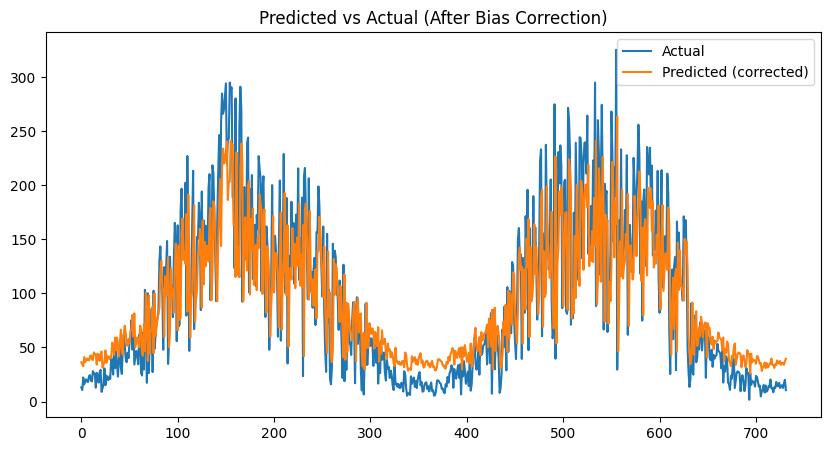

In [778]:
plt.figure(figsize=(10,5))
plt.plot(test['solarradiation'].values, label='Actual')
plt.plot(y_pred_corrected, label='Predicted (corrected)')
plt.legend()
plt.title('Predicted vs Actual (After Bias Correction)')
plt.show()

# Experiment 3:
To develop a LSTM Model for forecasting task applying **log transformation** technique to the target feature (solarradiation).

### Libraries

In [1]:
# Data manipulation
import numpy as np
import pandas as pd

# Scalling
from sklearn.preprocessing import MinMaxScaler
#  LSTM Model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Bidirectional
from tensorflow.keras.optimizers import Adam

# Early Stopping
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Plots
import matplotlib.pyplot as plt
import seaborn as sns

# Keras for randomsearch
import tensorflow as tf
import keras_tuner as kt
from sklearn.model_selection import ParameterGrid

# Statiscal Evaluation Metrics
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, mean_absolute_percentage_error
from math import sqrt

## Load the Data

In [160]:
df= pd.read_csv("Datasets/dublin_2015_to_2024_final.csv", parse_dates=["datetime"])
df = df.sort_index()


- parse_dates = ["datetime"] the time order is explicit
- sort_index() is to avoid shuffling 

## Natural logarithmic transformation

the original solar radiation variable exhibited a highly right-skewed distribution, with most values close to zero and few large peaks corresponding to maximum sunlight hours.
To normalize the distribution and stabilize variance, a natural logarithmic transformation 𝑦′=ln(1+𝑦) was applied.

Best practice in statistics: The use of log transformation (West, 2021) emphasises that log-transforming a right-skewed positive variable can help make distributions more symmetric.

In [161]:
df['solarradiation'] = np.log1p(df['solarradiation'])

In [101]:
df_org= pd.read_csv("dublin_2015_to_2024_final.csv", parse_dates=["datetime"])


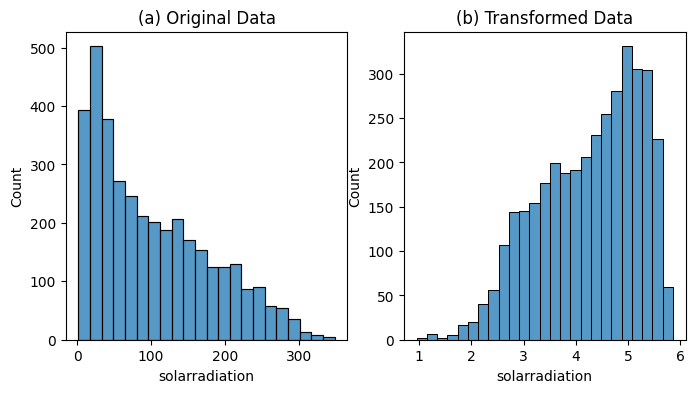

In [86]:
plt.figure(figsize=(8,4))
plt.subplot(1, 2, 1)
sns.histplot(df_org['solarradiation'])
plt.title("(a) Original Data")

plt.subplot(1, 2, 2)
sns.histplot(df['solarradiation'])
plt.title("(b) Transformed Data")
plt.show()

## Split data into Train(8 years) and Test(2 years)

The dataset was devided into train and test, with the purpuse of having real data for comparing model's prediction data

In [162]:
train = df[df['datetime'] < '2022-12-31']
test = df[df['datetime'] >= '2022-12-31'].copy()

set index

In [163]:
train.set_index("datetime", inplace=True)
test.set_index("datetime", inplace=True)


In [91]:
train.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2921 entries, 2015-01-01 to 2022-12-30
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   tempmax           2921 non-null   float64
 1   humidity          2921 non-null   float64
 2   precip            2921 non-null   float64
 3   windgust          2921 non-null   float64
 4   windspeed         2921 non-null   float64
 5   winddir           2921 non-null   float64
 6   sealevelpressure  2921 non-null   float64
 7   cloudcover        2921 non-null   float64
 8   visibility        2921 non-null   float64
 9   solarradiation    2921 non-null   float64
dtypes: float64(10)
memory usage: 251.0 KB


Note:

column 9 is the target feature

## Scaling

MinMaxScaler scale the data into a range or 0-1

In [164]:
scaler = MinMaxScaler()

train_scaled = scaler.fit_transform(train)
test_scaled= scaler.fit_transform(test)

## Make sequences

The create_sequence() function below divide the sequence into input/output patterns called samples, where lookback are the time steps used as input and horizon is the prediction

In [165]:
lookback = 30 # 30 days in memory
horizon = 1 # predicts next day

In [166]:
def create_sequences(data, lookback, horizon):
    X, y = [], []
    
    for i in range(lookback, len(data)- horizon+1):
        X.append(data[i-lookback:i,:])
        y.append(data[i + horizon-1, 9])  # 9 is Solarradiation feature
    return np.array(X), np.array(y)


- lookbak = how much past information is in memory
- horizon = how far ahead is predicting (1 predicts next day)

## X_train and y_train

computing create_sequences() function to create samples from train_scaled dataset

In [167]:
#Build train sequences from train_scaled

X_train, y_train = create_sequences(train_scaled, lookback, horizon)

In [168]:

X_train.shape

(2891, 30, 10)

In [169]:
y_train.shape

(2891,)

## History for test

test need some history, the last lookback rows are concatenated at the beginning of test

In [170]:
history = train_scaled[-lookback:,:]
test_history= np.vstack([history, test_scaled])

In [171]:
test_history.shape

(762, 10)

## create X_test, y_test

In [172]:
X_test, y_test = create_sequences(test_history, lookback, horizon)

In [173]:
X_test.shape,y_test.shape

((732, 30, 10), (732,))

## Build the  LSTM Model

The first layer that is added is an LSTM layer. The LSTM class accept several parameters:

- units, the number of LSTM neurons that are included in this layer
- return_sequences = True, this indicates that another LSTM layer will be added after the current layer already added.
- intup_shape, the number of timesteps and the number of predictors in out trainign data. Predictor is 1 ('solarradiation')

**Dropout regularization** is a technique used to avoid overfitting when training neural networks.
It involves randomly excluding or dropping out certain layer outputs during the training stage.
The dropout rate indicates how many neurons should be dropped in a specific layer of the neural network.

**Output Layer**, the Dense class will be the output layer. The parameter that has to be specified is units, which is the desired number of dimentions that the output layer should generate. 

TensorFlows allows to compile a nueral network, it accepts two arguments: optimizer and loss.

The Adam optimizer is useful in a wide variety of neural networks architectures.
The loss parameter is mean squared error, this is to measure the performance.

In [174]:
model = Sequential([
    LSTM( 64,return_sequences=True, input_shape=(lookback, X_train.shape[2])),
    Dropout(0.2),
    #Dense(horizon)
])
model.add(LSTM(units = 64, return_sequences = True))

model.add(Dropout(0.2))

model.add(LSTM(units = 64, return_sequences = True))

model.add(Dropout(0.2))

model.add(LSTM(units = 64))

model.add(Dropout(0.2))
model.add(Dense(units=1))
model.compile(optimizer='adam', loss='mse')
model.summary()

Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm_39 (LSTM)                       │ (None, 30, 64)              │          19,200 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_39 (Dropout)                 │ (None, 30, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_40 (LSTM)                       │ (None, 30, 64)              │          33,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_40 (Dropout)                 │ (None, 30, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_41 (LSTM)                       │ (None, 30, 64)              │          33,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_41 (Dropout)                 │ (None, 30, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_42 (LSTM)                       │ (None, 64)                  │          33,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_42 (Dropout)                 │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_12 (Dense)                     │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 118,337 (462.25 KB)

 Trainable params: 118,337 (462.25 KB)

 Non-trainable params: 0 (0.00 B)

## Training the Model

**EarlyStopping**

Stop training when a monitored metric has stopped improving. Assuming the goal of a training is to minimize the loss. 

In [175]:
es = EarlyStopping(monitor='val_loss', mode='min', verbose=1, patience=5)


The LSTM model is trained with X_train and y_train dataframes, 20% of the train data is been use as 'validation data'. This helps keras to evaluate loss on a separete dataset

In [176]:
history = model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=500,
    batch_size=32,
    callbacks=[es],
    shuffle=False,
    verbose=1
)


Epoch 1/500
73/73 ━━━━━━━━━━━━━━━━━━━━ 8s 37ms/step - loss: 0.1366 - val_loss: 0.0175
Epoch 2/500
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - loss: 0.0358 - val_loss: 0.0105
Epoch 3/500
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - loss: 0.0277 - val_loss: 0.0118
Epoch 4/500
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - loss: 0.0247 - val_loss: 0.0090
Epoch 5/500
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - loss: 0.0234 - val_loss: 0.0092
Epoch 6/500
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - loss: 0.0197 - val_loss: 0.0085
Epoch 7/500
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - loss: 0.0174 - val_loss: 0.0083
Epoch 8/500
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - loss: 0.0164 - val_loss: 0.0082
Epoch 9/500
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - loss: 0.0168 - val_loss: 0.0086
Epoch 10/500
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - loss: 0.0171 - val_loss: 0.0086
Epoch 11/500
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - loss: 0.0156 - val_loss: 0.0081
Epoch 12/500
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step

## Loss Plot

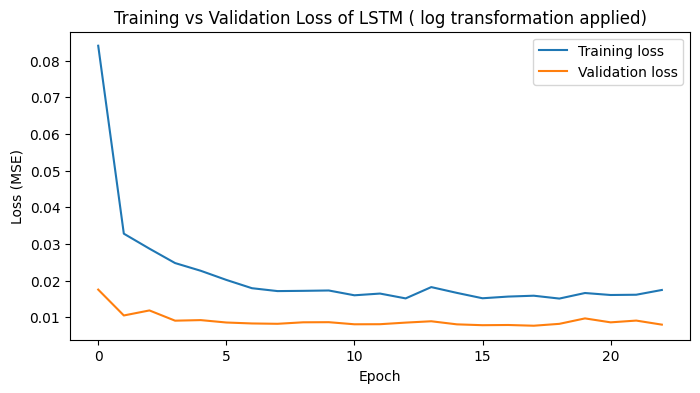

In [177]:
plt.figure(figsize=(8,4))
plt.plot(history.history['loss'], label='Training loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.title("Training vs Validation Loss of LSTM ( log transformation applied)")
plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.legend()
plt.show()

Observations:
- Validation and training loss decrase and flat
- Loss is stable
- no overfitting

## Predict

In [178]:
y_pred = model.predict(X_test)


23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step 


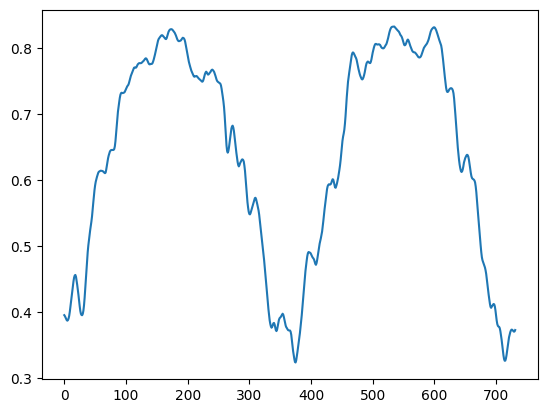

In [193]:
plt.plot(y_pred)

In [180]:
y_pred_inv_2=scaler_y.inverse_transform(y_pred)

## Unscale

In [107]:
y_pred_inv = scaler.inverse_transform(np.hstack((y_pred, #predictions
                                                 X_test[:, -1, 1:]
                                                )))[:,9] # solarradiation feature


### Inverse np.log1p()

In [194]:
y_pred_real = np.expm1(y_pred_inv_2)

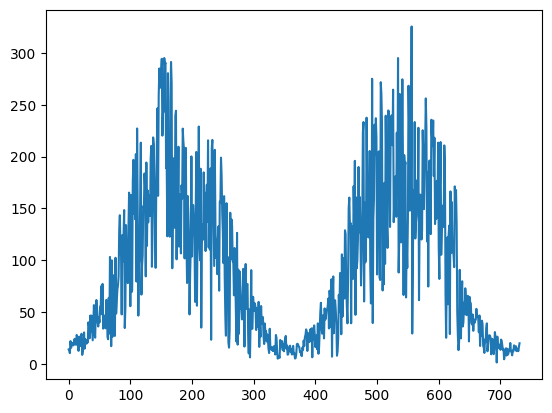

In [109]:
plt.plot(y_pred_real)

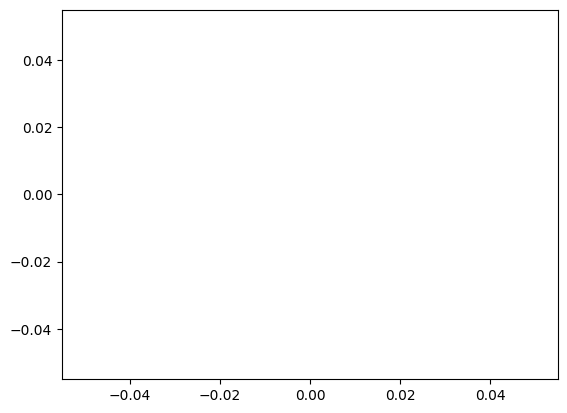

In [218]:
plt.plot(y_pred_real[0:1,:])

In [199]:
y_pred_real.shape

(732, 1)

## Actual vs Predicted Data Plot

In [189]:
df= pd.read_csv("Datasets/dublin_2015_to_2024_final.csv", parse_dates=["datetime"])
test_org = df[df['datetime'] >= '2022-12-31'].copy()

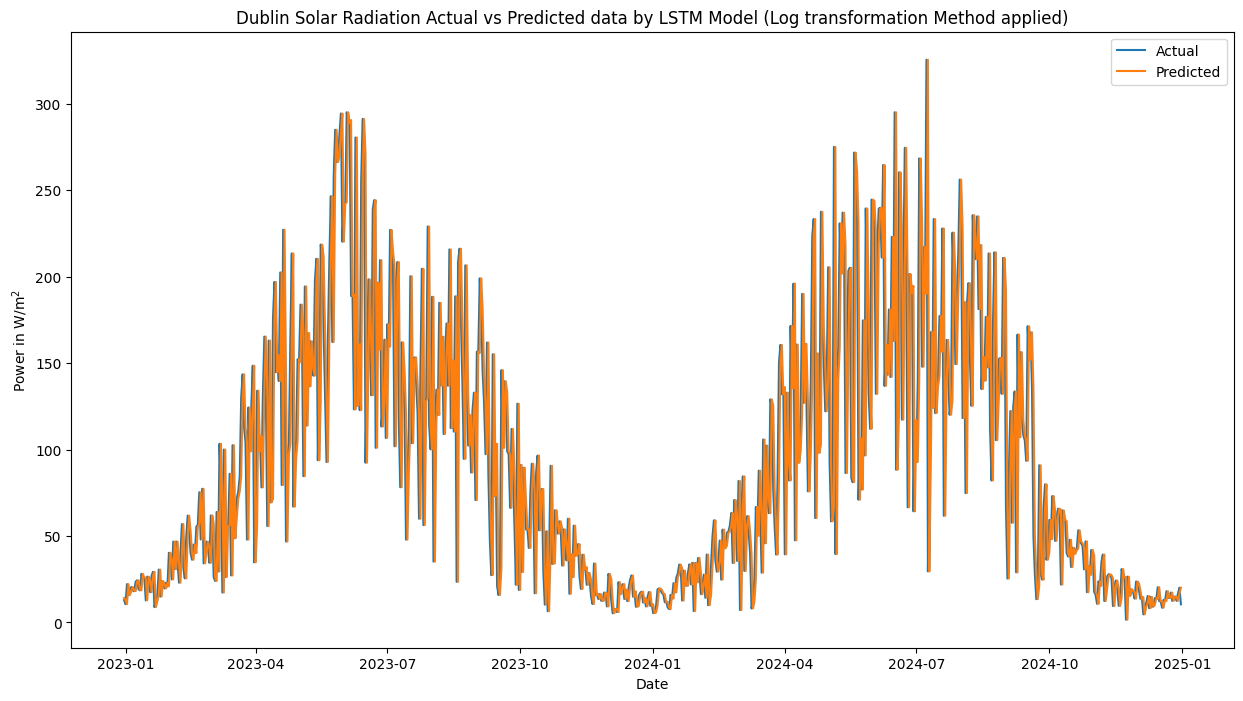

In [121]:
plt.figure(figsize=(15,8))
plt.plot(test_org['datetime'],test_org['solarradiation'], label="Actual")
plt.plot(test_org['datetime'],y_pred_real, label="Predicted")
plt.legend()
plt.title('Dublin Solar Radiation Actual vs Predicted data by LSTM Model (Log transformation Method applied)')
plt.xlabel('Date')
plt.ylabel('Power in W/m$^2$')
plt.show()


### Actual vs Predicted 60 days plot

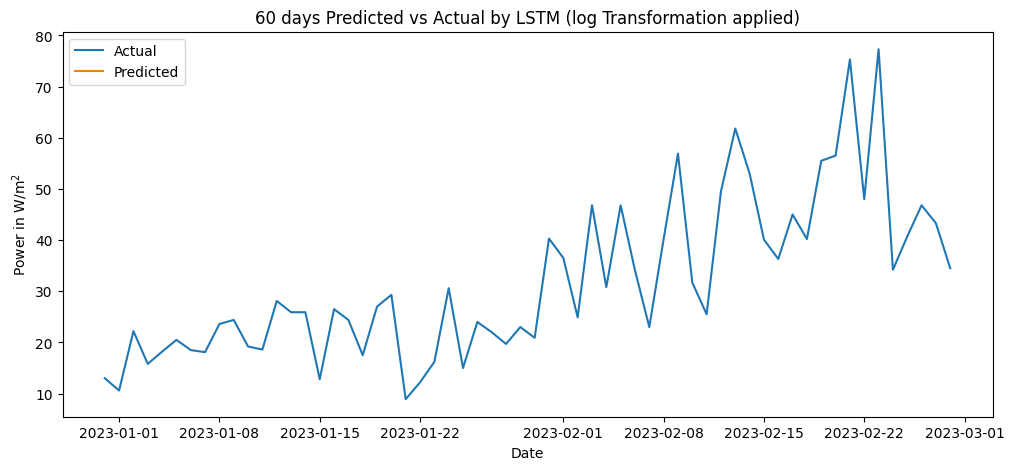

In [202]:
plt.figure(figsize=(12,5))
t=test_org['solarradiation']
plt.plot(test_org['datetime'][:60],t[:60], label="Actual")
plt.plot(test_org['datetime'][:60],y_pred_real[:60], label="Predicted")
plt.legend()
plt.title("60 days Predicted vs Actual by LSTM (log Transformation applied)")
plt.xlabel('Date')
plt.ylabel('Power in W/m$^2$')
plt.show()

## Accuracy

In [211]:
# Compute accuracy metrics
rmse = np.sqrt(mean_squared_error(test_org['solarradiation'], y_pred_inv_2))
mae = mean_absolute_error(test_org['solarradiation'], y_pred_inv_2)
r2 = r2_score(test_org['solarradiation'], y_pred_real)
mape=mean_absolute_percentage_error(test_org['solarradiation'], y_pred_inv_2)

print(f"RMSE: {rmse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"R² Score: {r2:.4f}")
print(f'MAPE: {mape:.4f}')

ValueError: Input contains infinity or a value too large for dtype('float64').

In [117]:
# Symmetric Mean Absolute Percentae Error Function
def smape(test, pred):
    test, pred = np.array(test), np.array(pred)
    return 100 * np.mean(2 * np.abs(pred - test) /
                         (np.abs(test) + np.abs(pred) + 1e-8))

print("SMAPE:", smape(test_org['solarradiation'], y_pred_real))

SMAPE: 42.03661686705319


## KerasTuner Bayesian Optimization

In [112]:
#  model function for BayesianOptimization 
def build_model(hp: kt.HyperParameters) -> tf.keras.Model:
    # search space
    units1   = hp.Int("units1", min_value=32, max_value=256, step=32)
    second_layer = hp.Boolean("use_second_lstm") # add other layer
    units2   = hp.Int("units2", 32, 256, step=32) if second_layer else None
    dropout  = hp.Float("dropout", 0.0, 0.5, step=0.1)
    rdropout = hp.Float("recurrent_dropout", 0.0, 0.5, step=0.1)
    lr       = hp.Choice("lr", [0.001, 0.0005, 0.0001])

    model = Sequential()
    # first LSTM
    model.add(LSTM(units1,
               input_shape=(lookback, n_features),
               return_sequences=second_layer,   # sequences 
               dropout=dropout,
               recurrent_dropout=rdropout))
    # second LSTM layer
    if second_layer:
        m.add(LSTM(units2,
                   return_sequences=False,
                   dropout=dropout,
                   recurrent_dropout=rdropout))
    # output dense
    model.add(Dense(1))

    model.compile(optimizer=Adam(learning_rate=lr),loss="mse", metrics=["mae"])
    return model

In [113]:
#  Bayesian optimization
tuner = kt.BayesianOptimization(
    build_model,
    objective="val_loss",          # minimize validation loss
    max_trials=10,                 # total models to do
    num_initial_points=5,          # random 
    overwrite=True,
    directory="kt_logs",        #save parameters
    project_name="lstm_bayes"
)

In [114]:
# early stopping
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True)
#reduce learning rate if validation loss stalls
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.5, patience=5, min_lr=1e-6)
# save the best parameters
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "best_lstm.h5", save_best_only=True, monitor="val_loss")



In [115]:
# search 
tuner.search(
    X_train, y_train,
    validation_split=0.2,     
    epochs=100,
    batch_size=kt.HyperParameters().Choice("batch_size", [16, 32, 64]),
    shuffle=False,            
    callbacks=[early_stop, reduce_lr, checkpoint],
    verbose=1
)




Trial 10 Complete [00h 00m 01s]

Best val_loss So Far: 0.006845341995358467
Total elapsed time: 00h 04m 45s


Print best Parameters

In [118]:
best_hp = tuner.get_best_hyperparameters(1)[0]
print("Best HP:", best_hp.values)

Best HP: {'units1': 256, 'use_second_lstm': False, 'dropout': 0.0, 'recurrent_dropout': 0.1, 'lr': 0.0001, 'units2': 96}


Model Using Best Parameters 

In [119]:
best_model = tuner.get_best_models(1)[0]
best_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 256)                 │         273,408 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 1)                   │             257 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 273,665 (1.04 MB)

 Trainable params: 273,665 (1.04 MB)

 Non-trainable params: 0 (0.00 B)

In [120]:
history_best= best_model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - loss: 0.0119 - mae: 0.0835 - val_loss: 0.0072 - val_mae: 0.0654
Epoch 2/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - loss: 0.0112 - mae: 0.0822 - val_loss: 0.0071 - val_mae: 0.0649
Epoch 3/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0102 - mae: 0.0779 - val_loss: 0.0074 - val_mae: 0.0700
Epoch 4/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - loss: 0.0111 - mae: 0.0827 - val_loss: 0.0069 - val_mae: 0.0653
Epoch 5/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - loss: 0.0105 - mae: 0.0796 - val_loss: 0.0069 - val_mae: 0.0646
Epoch 6/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - loss: 0.0099 - mae: 0.0773 - val_loss: 0.0075 - val_mae: 0.0707
Epoch 7/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - loss: 0.0113 - mae: 0.0837 - val_loss: 0.0069 - val_mae: 0.0658
Epoch 8/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - loss: 0.0107 - mae: 0.0800 - val_loss: 0.0075 - val_mae: 0.0647
Epoch 9/100
73/73 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - lo

### Train and validation plot

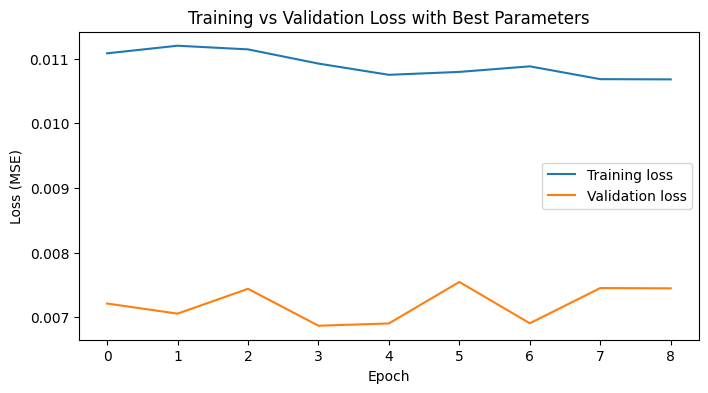

In [121]:
plt.figure(figsize=(8,4))
plt.plot(history_best.history['loss'], label='Training loss')
plt.plot(history_best.history['val_loss'], label='Validation loss')
plt.title("Training vs Validation Loss with Best Parameters")
plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.legend()
plt.show()

## Predict

In [122]:
y_pred = best_model.predict(X_test)


23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step 


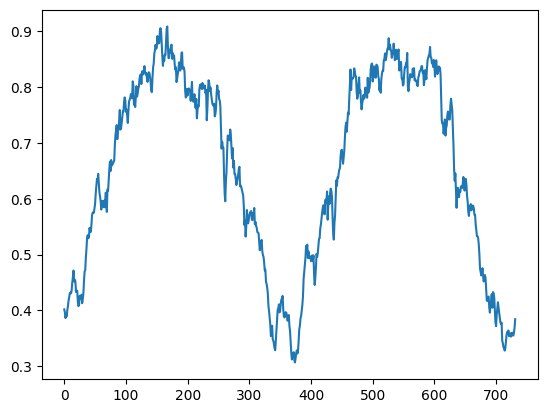

In [123]:
plt.plot(y_pred)

## Unscale

In [124]:
y_pred_inv = scaler.inverse_transform(np.hstack((y_pred, #predictions
                                                 X_test[:, -1, 1:]
                                                )))[:,9] # solarradiation feature


### Inverse np.log1p()

In [125]:
y_pred_real = np.expm1(y_pred_inv)

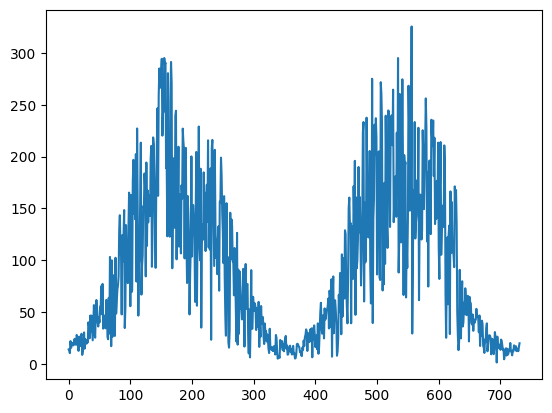

In [126]:
plt.plot(y_pred_real)

## Actual vs Predicted Data Plot

In [127]:
df= pd.read_csv("dublin_2015_to_2024_final.csv", parse_dates=["datetime"])
test_org = df[df['datetime'] >= '2022-12-31'].copy()

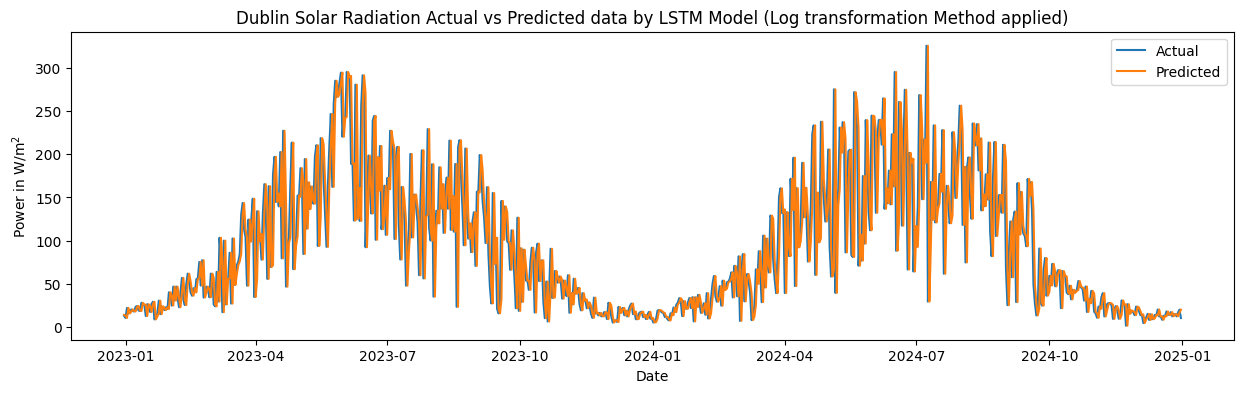

In [131]:
plt.figure(figsize=(15,4))
plt.plot(test_org['datetime'],test_org['solarradiation'], label="Actual")
plt.plot(test_org['datetime'],y_pred_real, label="Predicted")
plt.legend()
plt.title('Dublin Solar Radiation Actual vs Predicted data by LSTM Model (Log transformation Method applied)')
plt.xlabel('Date')
plt.ylabel('Power in W/m$^2$')
plt.show()


### Actual vs Predicted 60 days plot

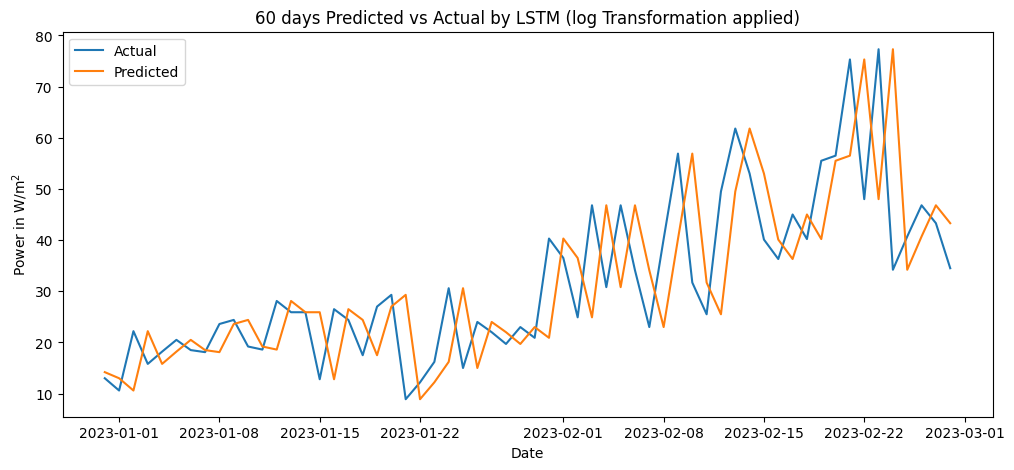

In [129]:
plt.figure(figsize=(12,5))
t=test_org['solarradiation']
plt.plot(test_org['datetime'][:60],t[:60], label="Actual")
plt.plot(test_org['datetime'][:60],y_pred_real[:60], label="Predicted")
plt.legend()
plt.title("60 days Predicted vs Actual by LSTM (log Transformation applied)")
plt.xlabel('Date')
plt.ylabel('Power in W/m$^2$')
plt.show()

## Accuracy

In [130]:
# Compute accuracy metrics
rmse = np.sqrt(mean_squared_error(test_org['solarradiation'], y_pred_real))
mae = mean_absolute_error(test_org['solarradiation'], y_pred_real)
r2 = r2_score(test_org['solarradiation'], y_pred_real)
mape=mean_absolute_percentage_error(test_org['solarradiation'], y_pred_real)

print(f"RMSE: {rmse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"R² Score: {r2:.4f}")
print(f'MAPE: {mape:.4f}')

RMSE: 54.4403
MAE: 36.1261
R² Score: 0.4679
MAPE: 0.5604


# Experiment 4:

To develop a forecasting Model using LSTM networks utilising **Cross-validation** technique. 




### Libraries

In [1]:
# Data manipulation
import numpy as np
import pandas as pd

# Scalling
from sklearn.preprocessing import MinMaxScaler
#  LSTM Model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Bidirectional
from tensorflow.keras.optimizers import Adam

# Early Stopping
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Plots
import matplotlib.pyplot as plt
import seaborn as sns

# Keras for randomsearch
import keras
import tensorflow as tf
import keras_tuner as kt
from sklearn.model_selection import ParameterGrid

# Statiscal Evaluation Metrics
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, mean_absolute_percentage_error
from math import sqrt

#time series split
from sklearn.model_selection import TimeSeriesSplit

## Load the Data

In [122]:
df = pd.read_csv("dublin_2015_to_2024_final.csv", parse_dates=["datetime"])
df = df.sort_index()


- parse_dates = ["datetime"] the time order is explicit
- sort_index() is to avoid shuffling 

## Split data into Train(8 years) and Test(2 years)

The dataset was devided into train and test, with the purpuse of having real data for comparing model's prediction data

In [123]:
train = df[df['datetime'] < '2022-12-31']
test = df[df['datetime'] >= '2022-12-31'].copy()

set index

In [124]:
train.set_index("datetime", inplace=True)
test.set_index("datetime", inplace=True)


In [818]:
train.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2921 entries, 2015-01-01 to 2022-12-30
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   tempmax           2921 non-null   float64
 1   humidity          2921 non-null   float64
 2   precip            2921 non-null   float64
 3   windgust          2921 non-null   float64
 4   windspeed         2921 non-null   float64
 5   winddir           2921 non-null   float64
 6   sealevelpressure  2921 non-null   float64
 7   cloudcover        2921 non-null   float64
 8   visibility        2921 non-null   float64
 9   solarradiation    2921 non-null   float64
dtypes: float64(10)
memory usage: 251.0 KB


Note:

column 9 is the target feature

In [819]:
test.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 732 entries, 2022-12-31 to 2024-12-31
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   tempmax           732 non-null    float64
 1   humidity          732 non-null    float64
 2   precip            732 non-null    float64
 3   windgust          732 non-null    float64
 4   windspeed         732 non-null    float64
 5   winddir           732 non-null    float64
 6   sealevelpressure  732 non-null    float64
 7   cloudcover        732 non-null    float64
 8   visibility        732 non-null    float64
 9   solarradiation    732 non-null    float64
dtypes: float64(10)
memory usage: 62.9 KB


## Make sequences

The create_sequence() function below divide the sequence into input/output patterns called samples, where lookback are the time steps used as input and horizon is the prediction

In [125]:
lookback = 30 # 30 days in memory
horizon = 1 # predicts next day

In [126]:
def create_sequences(data, lookback, horizon):
    X, y = [], []
    
    for i in range(lookback, len(data)- horizon+1):
        X.append(data[i-lookback:i,:])
        y.append(data[i + horizon-1, 9])  # 9 is Solarradiation feature
    return np.array(X), np.array(y)


- lookbak = how much past information is in memory
- horizon = how far ahead is predicting (1 predicts next day)

## Scaling

MinMaxScaler scale the data into a range or 0-1

In [127]:
scaler = MinMaxScaler()

train_scaled = scaler.fit_transform(train)
test_scaled= scaler.transform(test)

## X_train and y_train

computing create_sequences() function to create samples from train_scaled dataset

In [128]:
#Build train sequences from train_scaled

X_train, y_train = create_sequences(train_scaled, lookback, horizon)

In [129]:

X_train.shape

(2891, 30, 10)

In [130]:
y_train.shape

(2891,)

## History for test

test need some history, the last lookback rows are concatenated at the beginning of test

In [131]:
history = train_scaled[-lookback:,:]
test_history= np.vstack([history, test_scaled])

In [132]:
test_history.shape

(762, 10)

## create X_test, y_test

In [133]:
X_test, y_test = create_sequences(test_history, lookback, horizon)

In [134]:
X_test.shape,y_test.shape

((732, 30, 10), (732,))

## Cross-validation

Cross-validation is a technique used in machine learning to evaluate how well a model performs on unseen data by splitting the training dataset into multiple parts. It involves training the model on some parts and testing it on others.

Purpose of Cross-Validation:
- Prevent Overfitting: It reduces the risk of a model performing well on training data but poorly on new data.
- Model Evaluation: It provides a more reliable estimate of model performance compared to a simple train-test split.

In [137]:
tss = TimeSeriesSplit(n_splits=5)

In [138]:
fold_scores = []
accuracy_histories = []
loss_histories = []

# function for cross validation
for fold, (tr_idx, val_idx) in enumerate(tss.split((X_train)), start=1):
    X_tr, y_tr = X_train[tr_idx], y_train[tr_idx]
    X_val, y_val = X_train[val_idx], y_train[val_idx]

    # Build a fresh model each fold
    model = Sequential([
        LSTM(64, return_sequences=True, input_shape=(lookback, X_train.shape[2])),
        Dropout(0.2),
        LSTM(64, return_sequences=True),
        Dropout(0.2),
        LSTM(64, return_sequences=True),
        Dropout(0.2),
        LSTM(64),
        Dropout(0.2),
        Dense(1)
    ])

    model.compile(optimizer='adam', loss='mse')

    es = EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True
    )

    
  #training the model
    history = model.fit(
        X_tr, y_tr,
        validation_data=(X_val, y_val),
        epochs=200,
        batch_size=128,
        callbacks=[es],
        verbose=0
    )
    # Store validation accuracy and loss for all epochs
    accuracy_histories.append(history.history['loss'])
    loss_histories.append(history.history['val_loss'])
# Predicting
    y_pred = model.predict(X_val)
    
   # undo scalling
    y_pred_inv = scaler.inverse_transform(np.hstack((y_pred, #predictions
                                                X_val[:, -1, 1:]
                                               )))[:,9] # solarradiation feature

    # accuracy
    rmse = np.sqrt(mean_squared_error(y_val, y_pred))
    mae = mean_absolute_error(y_val, y_pred)
    r2 = r2_score(y_val, y_pred)
    mape=mean_absolute_percentage_error(y_val, y_pred)
# sace results of each training
    fold_scores.append(rmse)
    fold_scores.append(mae)
    fold_scores.append(r2)
    fold_scores.append(mape)
 

C:\Users\erick\anaconda3\envs\ca1\Lib\site-packages\keras\src\layers\rnn\rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step 


C:\Users\erick\anaconda3\envs\ca1\Lib\site-packages\keras\src\layers\rnn\rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step 


C:\Users\erick\anaconda3\envs\ca1\Lib\site-packages\keras\src\layers\rnn\rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step 


C:\Users\erick\anaconda3\envs\ca1\Lib\site-packages\keras\src\layers\rnn\rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step 


C:\Users\erick\anaconda3\envs\ca1\Lib\site-packages\keras\src\layers\rnn\rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step 


In [859]:
fold_scores

[np.float64(0.14953228642832922),
 0.11225976748202576,
 0.6079073194338067,
 0.5584235970942854,
 np.float64(0.14507077758857026),
 0.10767792039474157,
 0.5350765512281601,
 99235724087.0853,
 np.float64(0.1395620222599452),
 0.10229920090554995,
 0.538462546665982,
 0.8222259204606723,
 np.float64(0.1495223858309553),
 0.1123376330876562,
 0.5528588528245675,
 0.5832401178982333,
 np.float64(0.10604332456697935),
 0.07584391107442676,
 0.7256957432660953,
 0.5356656234283413]

In [139]:
fold_scores = np.array(fold_scores)
fold_score = pd.DataFrame(fold_scores.reshape(5, 4),
                       columns=['rmse','mae','r2','mape'])
fold_score

,rmse,mae,r2,mape
0,0.144929,0.107522,0.631675,5.047254e-01
1,0.144124,0.105028,0.541123,4.491732e+10
2,0.139997,0.103405,0.535579,7.270589e-01
3,0.147974,0.111751,0.562069,5.729342e-01
4,0.106045,0.074469,0.725688,4.712225e-01


In [140]:
print("Mean RMSE:", np.mean(fold_scores[0]))
print("Mean MAE:", np.mean(fold_scores[1]))
print("Mean R2 Score:", np.mean(fold_scores[2]))
print("Mean MAPE:", np.mean(fold_scores[3]))

Mean RMSE: 0.14492935917878355
Mean MAE: 0.10752240039755263
Mean R2 Score: 0.6316747171102228
Mean MAPE: 0.504725407352239


## Loss Plot

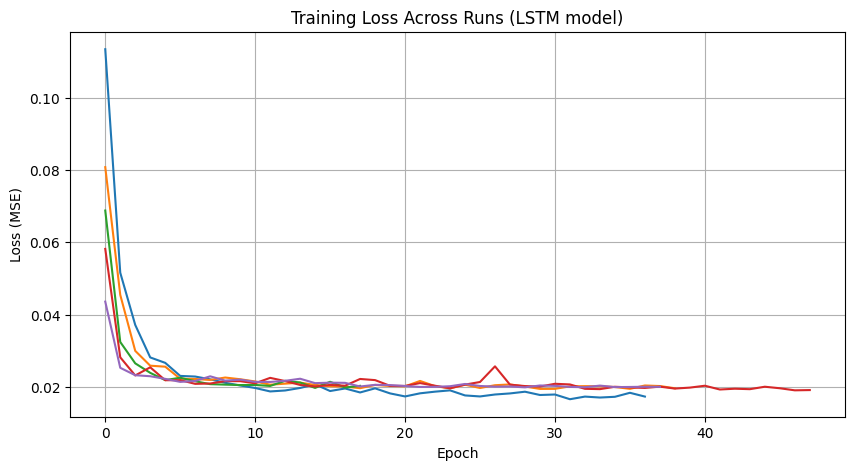

In [143]:
plt.figure(figsize=(10, 5))

for h in accuracy_histories:
    plt.plot(h)

plt.title("Training Loss Across Runs (LSTM model)")
plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.grid(True)
plt.show()

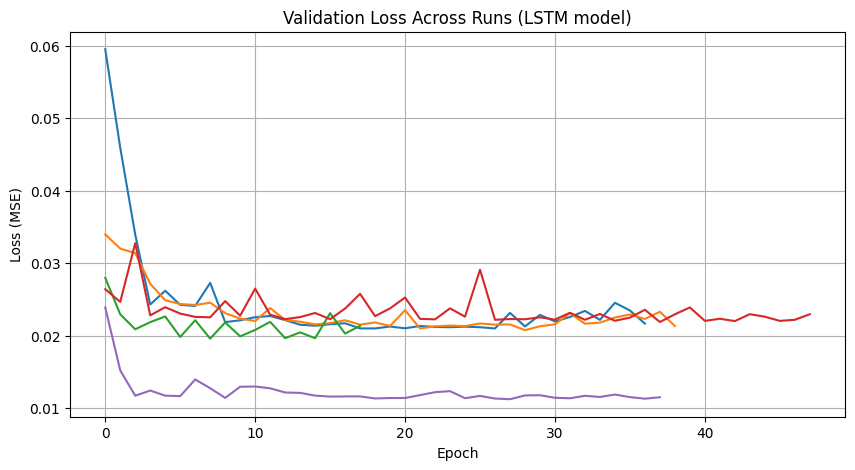

In [144]:
plt.figure(figsize=(10, 5))

for h in loss_histories:
    plt.plot(h)

plt.title("Validation Loss Across Runs (LSTM model)")
plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.grid(True)
plt.show()

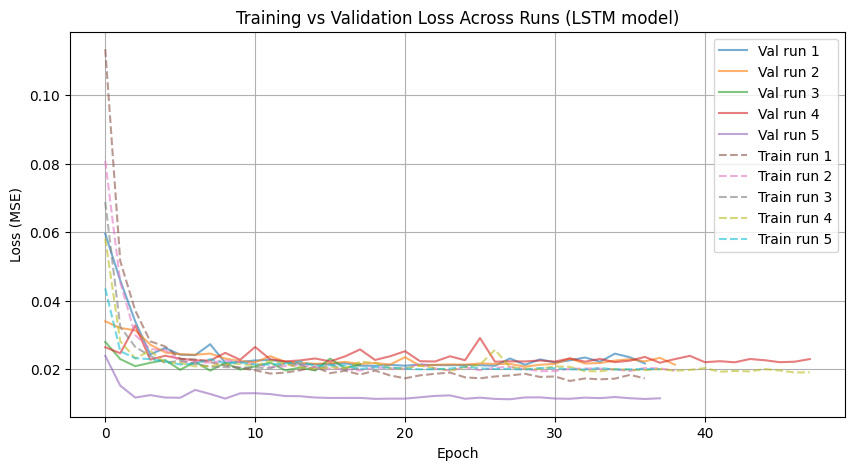

In [145]:
plt.figure(figsize=(10, 5))

for i, h in enumerate(loss_histories):
    plt.plot(h, label=f"Val run {i+1}", alpha=0.6)

for i, h in enumerate(accuracy_histories):
    plt.plot(h, linestyle="--", label=f"Train run {i+1}", alpha=0.6)

plt.title("Training vs Validation Loss Across Runs (LSTM model)")
plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.legend()
plt.grid(True)
plt.show()


Observations:
- All alidation and training loss decrase quickly
- Loss is stable
- no overfitting nor underfitting
  

In [146]:
y_pred = model.predict(X_test)


23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step


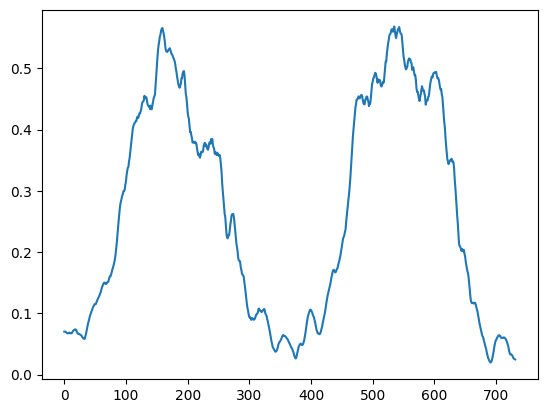

In [147]:
plt.plot(y_pred)

In [148]:
y_pred_inv = scaler.inverse_transform(np.hstack((y_pred, #predictions
                                                 X_test[:, -1, 1:]
                                                )))[:,9] # solarradiation feature


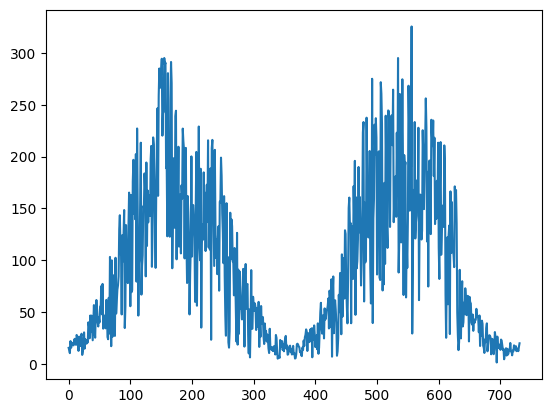

In [149]:
plt.plot(y_pred_inv)

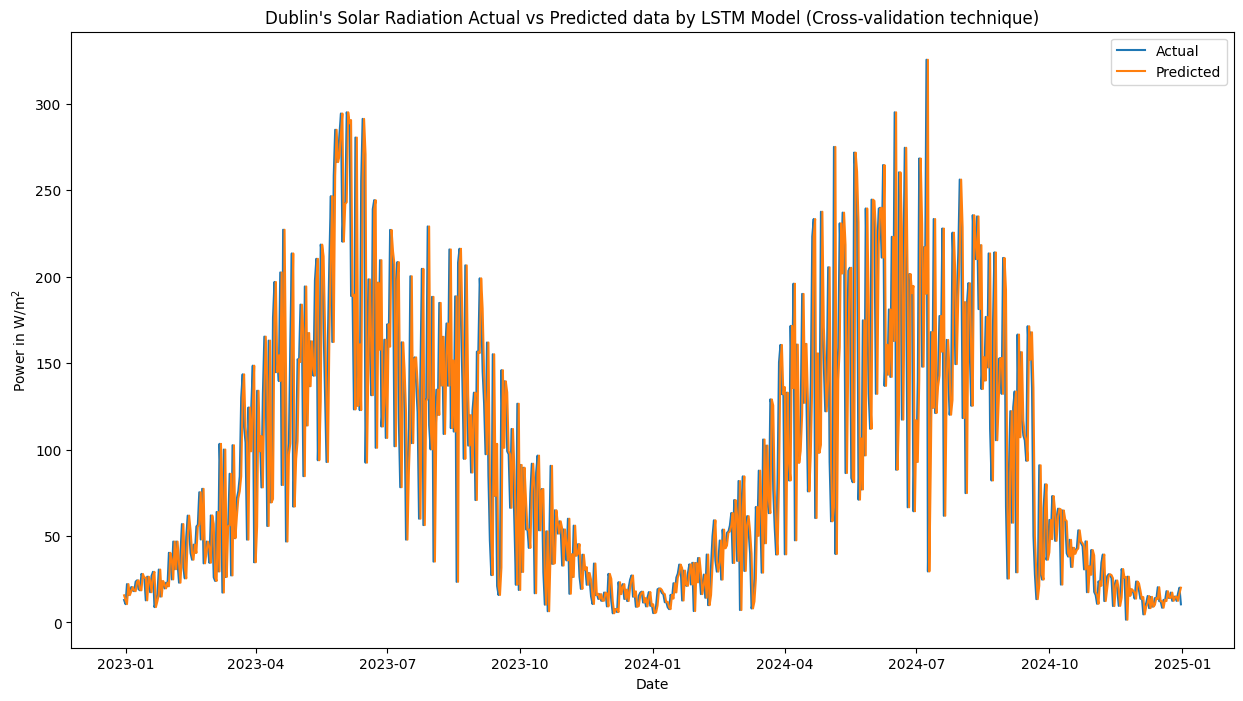

In [152]:
plt.figure(figsize=(15,8))
plt.plot(test.index,test['solarradiation'], label="Actual")
plt.plot(test.index,y_pred_inv, label="Predicted")
plt.legend()
plt.xlabel('Date')
plt.ylabel('Power in W/m$^2$')
plt.title("Dublin's Solar Radiation Actual vs Predicted data by LSTM Model (Cross-validation technique)")
plt.show()


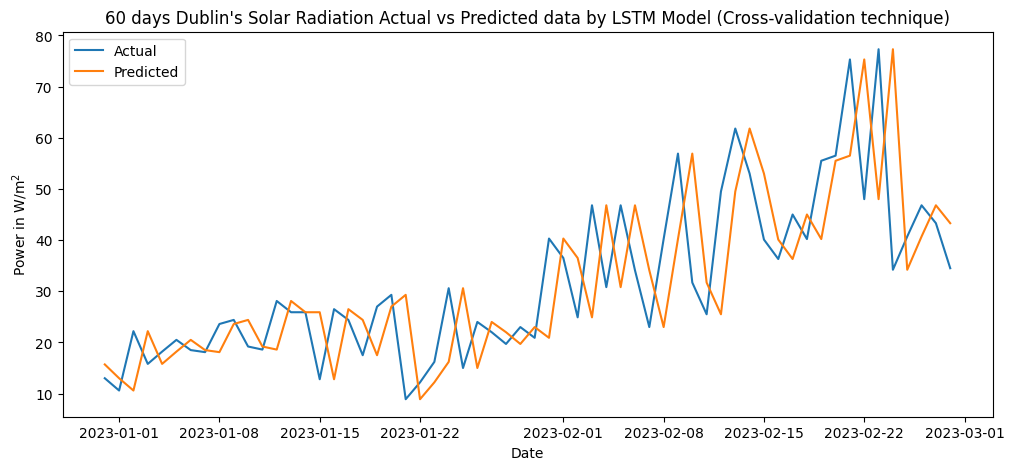

In [157]:
plt.figure(figsize=(12,5))
t=test['solarradiation']
plt.plot(test.index[:60],t[:60], label="Actual")
plt.plot(test.index[:60],y_pred_inv[:60], label="Predicted")
plt.legend()
plt.xlabel('Date')
plt.ylabel('Power in W/m$^2$')
plt.title("60 days Dublin's Solar Radiation Actual vs Predicted data by LSTM Model (Cross-validation technique)")
plt.show()

### Accurracy

In [158]:
# Compute accuracy metrics
rmse = np.sqrt(mean_squared_error(test['solarradiation'], y_pred_inv))
mae = mean_absolute_error(test['solarradiation'], y_pred_inv)
r2 = r2_score(test['solarradiation'], y_pred_inv)
mape=mean_absolute_percentage_error(test['solarradiation'], y_pred_inv)

print(f"RMSE: {rmse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"R² Score: {r2:.4f}")
print(f'MAPE: {mape:.4f}')

RMSE: 54.4403
MAE: 36.1281
R² Score: 0.4679
MAPE: 0.5605


In [159]:
# Symmetric Mean Absolute Percentae Error Function
def smape(test, pred):
    test, pred = np.array(test), np.array(pred)
    return 100 * np.mean(2 * np.abs(pred - test) /
                         (np.abs(test) + np.abs(pred) + 1e-8))

print("SMAPE:", smape(test['solarradiation'], y_pred_inv))

SMAPE: 42.05033818096619


## Save the model

In [849]:
# Save model
model.save('lstm_cros_validation.keras')

In [958]:
#load the model
model=keras.models.load_model('lstm_cros_validation.keras')

# Expetiment 5:
Predicting 30 days ahead

### Load the data

In [2]:
df=pd.read_csv('dublin_2015_to_2024_final.csv', parse_dates=['datetime'])

In [3]:
df.index = pd.to_datetime(df['datetime'])
df = df.sort_index()

In [4]:
df.head()

,datetime,tempmax,humidity,precip,windgust,windspeed,winddir,sealevelpressure,cloudcover,visibility,solarradiation
datetime,,,,,,,,,,,
2015-01-01,2015-01-01,13.6,82.9,4.786,95.8,64.0,220.5,1013.4,86.1,17.1,8.8
2015-01-02,2015-01-02,7.0,73.1,0.451,68.5,40.9,241.5,1026.9,49.4,20.9,39.2
2015-01-03,2015-01-03,6.1,93.9,7.283,37.1,28.1,301.3,1023.8,64.0,15.6,16.9
2015-01-04,2015-01-04,6.8,93.5,0.000,33.8,13.1,191.4,1031.3,54.9,18.9,20.1
2015-01-05,2015-01-05,10.7,88.6,0.026,41.4,25.5,182.2,1021.3,89.5,19.8,9.8


### Feature Engineering

In [5]:
FEATURES = ['tempmax', 'humidity', 'precip', 'windgust', 'windspeed',
            'winddir', 'sealevelpressure', 'cloudcover', 'visibility',
            'solarradiation']

TARGET = 'solarradiation'

select exogenous data

In [6]:
EXOG = [c for c in FEATURES if c != TARGET]

### create x and y

In [7]:
# feature and target arrays
X_all = df[FEATURES].values      
y_all = df[TARGET].values.reshape(-1, 1)


### Scalling

In [8]:
#using two scaler to prevent data leaking
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

X_all_scaled = scaler_X.fit_transform(X_all)          
y_all_scaled = scaler_y.fit_transform(y_all).ravel() 

### Make sequences

In [9]:
lookback = 30      # number of past days to feed into LSTM
n_features =X_all_scaled.shape[1] 

In [10]:
def make_sequences(X, y, lookback):
    X_seq, y_seq = [], []
    for i in range(lookback, len(X)):
        X_seq.append(X[i-lookback:i, :])  # window of features
        y_seq.append(y[i])                # next-day target
    return np.array(X_seq), np.array(y_seq)

X_seq, y_seq = make_sequences(X_all_scaled, y_all_scaled, lookback)

print("X_seq shape:", X_seq.shape)  # (samples, lookback, 10)
print("y_seq shape:", y_seq.shape)  # (samples,)


X_seq shape: (3623, 30, 10)
y_seq shape: (3623,)


### LSTM model

In [12]:
#Best parameters: {'units1': 128, 'use_second_lstm': False, 'dropout': 0.0, 'recurrent_dropout': 0.2, 'lr': 0.001, 'units2': 128
model = Sequential([
    LSTM(128, return_sequences=True,recurrent_dropout=0.2, input_shape=(lookback, n_features)),
    Dropout(0.0),
    LSTM(128),
    Dropout(0.0),
    Dense(1)
])


model.compile(optimizer=tf.keras.optimizers.Adam(0.001), loss='mse')

es = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_seq, y_seq,
    validation_split=0.2,
    epochs=100,
    batch_size=64,
    callbacks=[es],
    verbose=0
)


C:\Users\erick\anaconda3\envs\ca1\Lib\site-packages\keras\src\layers\rnn\rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Text(0.5, 1.0, 'loss vs val loss of LSTM (Predicting future Experiment)')

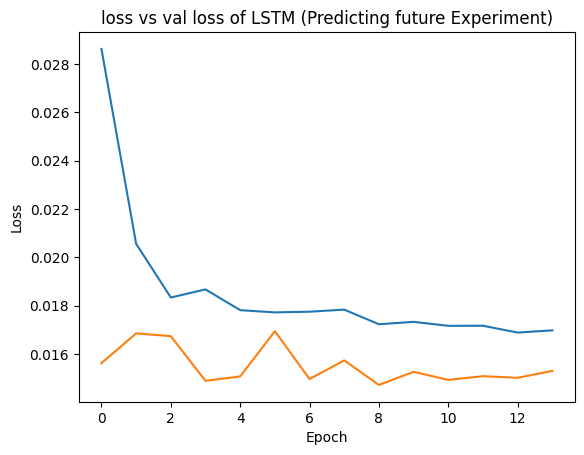

In [13]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('loss vs val loss of LSTM (Predicting future Experiment)')

### Day-of-year median function

This method refers to the analysis of the median over multiple years for specific days of the year. This approach helps identify patterns and trends in data.

In [14]:
def make_seasonal_data(df, exog_cols=EXOG):
    df = df.copy()
    df.index = pd.to_datetime(df.index)
    df['doy'] = df.index.dayofyear #1 - 365
    df['hour'] = 0  # daily data gives hour=0
    data = (
        df.groupby(['doy', 'hour'])[exog_cols] #creating day of day and hour, hour is o, we olnly have daily data
          .median() #median
          .reset_index()
    )
    return data


### create 30 day exogenous data

this function creates a future dataframe of exogenous features by doy median

In [18]:
def make_future_data(df, start_date, periods, exog_cols=EXOG):
    df = df.copy() #use a copy of df
    df.index = pd.to_datetime(df.index) #define index 
   
     #using day of year function
    data = make_seasonal_data(df, exog_cols=EXOG) 
    data = data.set_index(['doy','hour'])

    # future daily index
    future_index = pd.date_range(start=start_date, periods=periods, freq='D')
# create future dataframe with doy values
    df_future = pd.DataFrame(index=future_index)
    df_future['doy'] = df_future.index.dayofyear
    df_future['hour'] = 0 #hour is zero, it's daily data
    
    #loop to fill in with the doy seasonal value
    rows = []
    for x in df_future.index:
        key = (x.dayofyear, 0)
        if key in data.index:
            rows.append(data.loc[key, exog_cols].values)

            # create a dataframe with future index and exogenous DOY median data
    df_future_exog = pd.DataFrame(rows, index=future_index, columns=exog_cols)
    df_future_exog[TARGET] = np.nan
    return df_future_exog


### Create future dataframe

In [19]:
future= make_future_data(
    df=df,
    start_date='2025-01-01',
    periods=30,
    exog_cols=EXOG
)


In [22]:
future.head()

,tempmax,humidity,precip,windgust,windspeed,winddir,sealevelpressure,cloudcover,visibility,solarradiation
2025-01-01,7.85,84.35,0.8515,60.85,29.70,231.05,1010.45,61.80,16.30,NaN
2025-01-02,8.50,84.05,0.3145,59.40,31.15,226.55,1011.90,52.35,17.30,NaN
2025-01-03,7.75,86.35,0.7220,52.35,29.45,251.30,1014.10,64.00,16.85,NaN
2025-01-04,6.95,86.35,0.0525,42.65,22.50,239.60,1017.70,68.10,17.80,NaN
2025-01-05,7.10,85.55,0.0155,41.20,23.95,214.50,1019.20,73.90,18.60,NaN


In [24]:
future_scaled= scaler_X.transform(future)

C:\Users\erick\anaconda3\envs\ca1\Lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but MinMaxScaler was fitted without feature names
  warnings.warn(


In [25]:
future_scaled.shape

(30, 10)

### Predict 30 days

In [82]:
window_scaled = X_all_scaled[-lookback:, :].copy()   #starting window
future_dates = future.index


### Autoregresive function

In [83]:
future_preds_orig = []

for i in future_dates:
    # input to predict, starting with first window
    x_input = window_scaled.reshape(1, lookback, n_features)

        # predict next target 
    y_next_scaled = model.predict(x_input, verbose=0)[0, 0]

        # invert to original units
    y_next_orig = scaler_y.inverse_transform([[y_next_scaled]])[0, 0]
    future_preds_orig.append(y_next_orig)

        # build full feature row in original units
    exog_orig = future.loc[i, EXOG].values.astype(float)  #i get exogenous for date
                                                          # EXOG are exogenous colums
    row_orig = np.concatenate([exog_orig, [y_next_orig]])  #append the predicted value

        # scale this row to put back into the window
    row_scaled = scaler_X.transform(row_orig.reshape(1, -1))[0] #scaling again
                                                                #[0] get 1D vector

        # update sliding window with new row
    window_scaled = np.vstack([window_scaled[1:], row_scaled]) #[1:] drops the oldest row or first day
                                                               #vstack arrays in vertical sequence

### create a dataframe

In [84]:
forecast_series = pd.Series(
        future_preds_orig,
        index=future_dates,
        name='forecast_solarradiation_by lstm')

In [85]:
forecast_series.head()

2025-01-01    19.514833
2025-01-02    20.774403
2025-01-03    22.379678
2025-01-04    21.843818
2025-01-05    19.955057
Freq: D, Name: forecast_solarradiation_by lstm, dtype: float64

### saving forecasted dataset

In [36]:
forecast_series.to_csv('forecast_by_LSTM.csv',index=True)

### Plot History + prediction

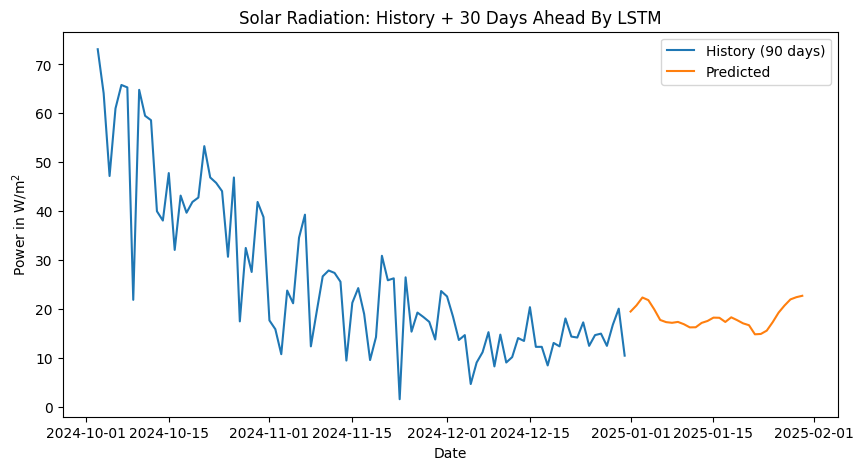

In [86]:
plt.figure(figsize=(10,5))

plt.plot(df['solarradiation'][-90:], label='History (90 days)')
plt.plot(forecast_series, label='Predicted')
plt.legend()
plt.title('Solar Radiation: History + 30 Days Ahead By LSTM')
plt.xlabel('Date')
plt.ylabel('Power in W/m$^2$')
plt.show()

test need some history, the last lookback rows are concatenated at the beginning of test

# Predicting the future Experiment 30 days window by RepeatVector

In [125]:
df=pd.read_csv('dublin_2015_to_2024_final.csv',parse_dates=["datetime"])

In [126]:
df.set_index('datetime',inplace=True)

In [127]:
# df is your full dataframe with all features + 'radiation'
target_col = 'solarradiation'
exog_cols = [c for c in df.columns if c != target_col]

scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

X_all = scaler_X.fit_transform(df[exog_cols])        # exogenous inputs
y_all = scaler_y.fit_transform(df[[target_col]])     # radiation only


In [135]:
X_all.shape

(3653, 9)

In [128]:
window_size = 30   # past days used as input
n_future   = 30    # days ahead to predict

X, y = [], []

for i in range(window_size, len(df) - n_future + 1):
    # past exogenous features
    X.append(X_all[i-window_size:i, :])          # shape: (30, n_exog_features)
    # future radiation only
    y.append(y_all[i:i+n_future, 0])             # shape: (30,)

X = np.array(X)                                  # (samples, 30, n_exog_features)
y = np.array(y).reshape(-1, n_future, 1)         # (samples, 30, 1)


In [137]:
X.shape,y.shape

((3594, 30, 9), (3594, 30, 1))

In [129]:
from keras.models import Sequential
from keras.layers import LSTM, Dense, RepeatVector, TimeDistributed

n_features = X.shape[2]

model = Sequential([
    LSTM(128, activation='tanh', input_shape=(window_size, n_features)),
    RepeatVector(n_future),
    LSTM(128, activation='tanh', return_sequences=True),
    TimeDistributed(Dense(1))   # predict radiation only
])

model.compile(optimizer='adam', loss='mse')
#model.summary()
es = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history = model.fit(X, y, epochs=50, batch_size=64, callbacks= [es], validation_split=0.2, verbose=1)


Epoch 1/50


C:\Users\erick\anaconda3\envs\ca1\Lib\site-packages\keras\src\layers\rnn\rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


45/45 ━━━━━━━━━━━━━━━━━━━━ 6s 61ms/step - loss: 0.0733 - val_loss: 0.0318
Epoch 2/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - loss: 0.0359 - val_loss: 0.0311
Epoch 3/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - loss: 0.0310 - val_loss: 0.0385
Epoch 4/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - loss: 0.0309 - val_loss: 0.0302
Epoch 5/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - loss: 0.0269 - val_loss: 0.0279
Epoch 6/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - loss: 0.0269 - val_loss: 0.0277
Epoch 7/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - loss: 0.0248 - val_loss: 0.0276
Epoch 8/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - loss: 0.0227 - val_loss: 0.0317
Epoch 9/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - loss: 0.0246 - val_loss: 0.0279
Epoch 10/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - loss: 0.0224 - val_loss: 0.0332
Epoch 11/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - loss: 0.0257 - val_loss: 0.0273
Epoch 12/50
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - loss: 0.0218 - val_l

In [132]:
# last 30 rows of exogenous features
last_X = X_all[-window_size:, :]                       # (30, n_exog_features)
last_X = last_X.reshape(1, window_size, n_features)    # (1, 30, n_features)

y_pred_scaled = model.predict(last_X)[0]               # (30, 1)

# invert scaling to real radiation units
y_pred = scaler_y.inverse_transform(y_pred_scaled)     # (30, 1)

# build future date index
future_index = pd.date_range(start=df.index[-1] + pd.Timedelta(days=1),
                             periods=n_future, freq='D')

forecast_df = pd.DataFrame({'radiation_forecast': y_pred.flatten()},
                           index=future_index)


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 510ms/step


In [133]:
forecast_df

,radiation_forecast
2025-01-01,38.807877
2025-01-02,48.117702
2025-01-03,50.517323
2025-01-04,50.450764
2025-01-05,49.731892
2025-01-06,49.023182
2025-01-07,48.512501
2025-01-08,48.210831
2025-01-09,48.075733
2025-01-10,48.058262


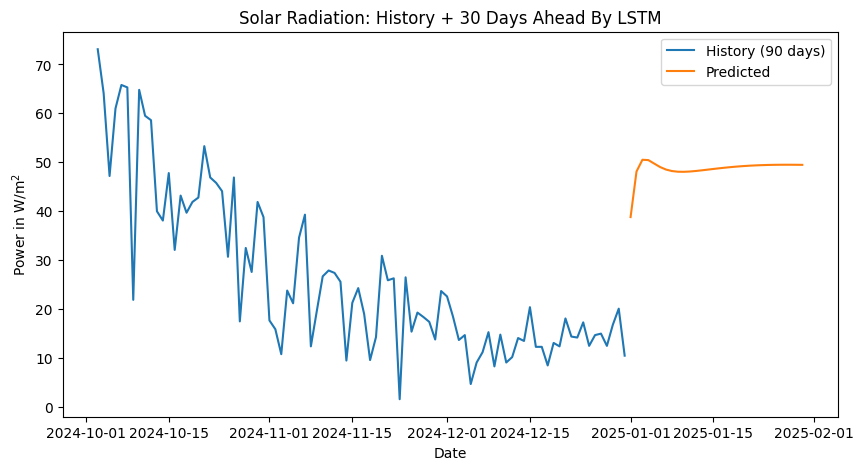

In [134]:
plt.figure(figsize=(10,5))

plt.plot(df['solarradiation'][-90:], label='History (90 days)')
plt.plot(forecast_df, label='Predicted')
plt.legend()
plt.title('Solar Radiation: History + 30 Days Ahead By LSTM')
plt.xlabel('Date')
plt.ylabel('Power in W/m$^2$')
plt.show()